In [1]:
!pip install transformers

In [2]:
pip install protobuf==3.20.3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.1/162.1 kB 14.1 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 3.20.3 which is incompatible.
wandb 0.25.1 requires protobuf!=5.28.0,!=5.29.0,<7,>4.21.0, but you have protobuf 3.20.3 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 3.20.3 which is incompatible.
opentelemetry-proto 1.38.0 requires protobuf<7.0,>=5.0, but you have protobuf 3.20.3 which is incompatible.
grain 0.2.16 requires protobuf>=5.28.3, but you have protobuf 3.20.3 which is incompatible.
google-api-core 2.30.0 requires protobuf<7.0.0,>=4.25.8, but you

In [3]:
import transformers
print(transformers.__version__)

import torch
print(torch.__version__)
print(torch.version.cuda)

5.0.0
2.10.0+cu128
12.8


In [4]:
import os
import pickle
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from torch.optim import AdamW
from torch.utils.data import (DataLoader, RandomSampler, SequentialSampler, TensorDataset)
from transformers import BertModel, BertTokenizer
from transformers.optimization import get_linear_schedule_with_warmup
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

In [5]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f'There are {torch.cuda.device_count()} GPU(s) available.')
    print('Device name:', torch.cuda.get_device_name(0))

else:
    print('No GPU available, using the CPU instead.')
    device = torch.device("cpu")

There are 1 GPU(s) available.
Device name: NVIDIA L4


In [6]:
# load data from drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
# --- TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ---
dataset_file_path = '/content/drive/MyDrive/Bert/Data/booking_sent_analysis_data.pkl'
# Ánh xạ nhãn gốc (dạng chuỗi điểm) sang số nguyên từ 0-9
encoded_label_dict = {str(i): i - 1 for i in range(1, 11)}

with open(dataset_file_path, 'rb') as pf:
    loaded_data = pickle.load(pf)
    review_data_records = loaded_data['review_data_records']
    original_labels_str = loaded_data['labels']

    # Chuyển nhãn sang số nguyên (0-9)
    original_labels_int = [encoded_label_dict[str(int(float(label)))] for label in original_labels_str]

    # Vì các nhãn thực tế có thể không đủ 10 lớp (ví dụ chỉ từ 5-10 điểm),
    # chúng ta cần ánh xạ lại chúng về một dãy bắt đầu từ 0.
    unique_labels_sorted = sorted(list(set(original_labels_int)))
    remapping_dict = {old_label: new_label for new_label, old_label in enumerate(unique_labels_sorted)}
    print(f"Ánh xạ lại các nhãn: {remapping_dict}")

    # Nhãn cuối cùng để huấn luyện mô hình, bắt đầu từ 0
    final_labels = [remapping_dict[l] for l in original_labels_int]

    # Tách các thành phần dữ liệu
    hotel_other_info = [record[0] for record in review_data_records]
    textual_review_docs = [record[1] for record in review_data_records]
    review_other_info = [record[2] for record in review_data_records]

    print(f'\nTổng số bản ghi review đã tải: [{len(textual_review_docs)}]')
    NUM_CLASSES = len(set(final_labels))
    print(f'Tổng số lớp (sau khi ánh xạ): [{NUM_CLASSES}]')
    print(f"Các nhãn mới: {sorted(list(set(final_labels)))}")
# Sau phần:
# review_data_records = loaded_data['review_data_records']
# original_labels_str = loaded_data['labels']

print("\n=== 5 MẪU ĐẦU TIÊN CỦA DỮ LIỆU ===")
for i in range(min(5, len(review_data_records))):
    hotel_info = review_data_records[i][0]          # Thông tin khách sạn (dict/list/str)
    review_text = review_data_records[i][1]         # Nội dung đánh giá văn bản
    other_info = review_data_records[i][2]          # Thông tin khác của review

    print(f"\nMẫu {i+1}:")
    print("  - Nhãn gốc (string):", original_labels_str[i])
    print("  - Nhãn đã mã hóa (sau remap):", final_labels[i])
    print("  - Hotel other info:", hotel_info)
    print("  - Textual review (nội dung đánh giá):")
    print("   ", review_text[:300] + "..." if len(review_text) > 300 else review_text)
    print("  - Review other info:", other_info)
    print("-" * 100)


Ánh xạ lại các nhãn: {4: 0, 5: 1, 6: 2, 7: 3, 8: 4, 9: 5}

Tổng số bản ghi review đã tải: [41136]
Tổng số lớp (sau khi ánh xạ): [6]
Các nhãn mới: [0, 1, 2, 3, 4, 5]

=== 5 MẪU ĐẦU TIÊN CỦA DỮ LIỆU ===

Mẫu 1:
  - Nhãn gốc (string): 10
  - Nhãn đã mã hóa (sau remap): 5
  - Hotel other info: [8.4, 7.9, 7.9, 8.0, 8.0, 8.5, 8.2]
  - Textual review (nội dung đánh giá):
    xuất_sắc tốt về chất_lượng phòng cảm_quan thấy ổn_áp
  - Review other info: [408, 1, 3]
----------------------------------------------------------------------------------------------------

Mẫu 2:
  - Nhãn gốc (string): 8
  - Nhãn đã mã hóa (sau remap): 3
  - Hotel other info: [8.5, 7.7, 8.0, 8.0, 8.3, 8.9, 8.5]
  - Textual review (nội dung đánh giá):
    tiếc là đi vào ngày trời âm_u biển động mà con lớn lại sốt nên không đi chơi tốt nhiều chỗ nghỉ gần bãi biển đi bộ_xíu là tới
  - Review other info: [1205, 3, 0]
----------------------------------------------------------------------------------------------------

Mẫu 3:


In [8]:
def numerical_to_array(X):
    hotel_features = []
    review_features = []

    for idx, item in enumerate(X):
        try:
            hotel = item[0]
            review = item[2]
            if not (isinstance(hotel, (list, tuple)) and isinstance(review, (list, tuple))):
                raise ValueError(f"Mẫu {idx}: numerical không phải list")
        except IndexError as e:
            print(f"Lỗi tại mẫu {idx}: {e} - Nội dung: {item}")
            raise  # Dừng để xem mẫu lỗi

        hotel_features.append(hotel)
        review_features.append(review)

    hotel_array = np.array(hotel_features, dtype=float)
    review_array = np.array(review_features, dtype=float)
    return np.hstack([hotel_array, review_array])

In [9]:
import pandas as pd
from collections import Counter

# 1. Đếm nhãn gốc dạng string (chính xác nhất)
print("\n=== Số lượng từng nhãn gốc (dạng chuỗi) ===")
label_counts_str = Counter(original_labels_str)
for label, count in sorted(label_counts_str.items(), key=lambda x: float(x[0])):
    print(f"Nhãn {label:>4}: {count:>6} mẫu  ({count/len(original_labels_str)*100:.2f}%)")

# 2. Đếm nhãn đã chuyển sang int (sau khi parse float → int)
labels_int = [int(float(l)) for l in original_labels_str]
label_counts_int = Counter(labels_int)
print("\n=== Số lượng từng nhãn sau khi chuyển sang số nguyên ===")
for label, count in sorted(label_counts_int.items()):
    print(f"Nhãn {label:>2}: {count:>6} mẫu  ({count/len(labels_int)*100:.2f}%)")

# 3. Đếm nhãn cuối cùng sau remapping (final_labels)
print("\n=== Số lượng từng lớp sau remapping (dùng để train) ===")
final_counts = Counter(final_labels)
for new_label, count in sorted(final_counts.items()):
    # Tìm nhãn gốc tương ứng
    original_label = [k for k, v in remapping_dict.items() if v == new_label][0]
    print(f"Lớp {new_label} (tương ứng nhãn gốc {original_label}): {count:>6} mẫu")

print(f"\nTổng số mẫu: {len(original_labels_str)}")


class_counts = np.zeros(6, dtype=int)  # khởi tạo 6 phần tử = 0

for new_label, count in final_counts.items():
    class_counts[new_label] = count

# Nếu bạn chắc chắn đã có đầy đủ 6 lớp (0-5), có thể viết gọn hơn:
# class_counts = np.array([final_counts.get(i, 0) for i in range(6)])

total_samples = sum(class_counts)          # hoặc len(final_labels)
num_classes = len(class_counts)            # thường = 6

# In ra kiểm tra
print("\n=== 3 biến cần lấy ra ===")
print(f"class_counts  = np.array({class_counts.tolist()})")
print(f"total_samples = {total_samples}")
print(f"num_classes   = {num_classes}")


=== Số lượng từng nhãn gốc (dạng chuỗi) ===
Nhãn    5:   1053 mẫu  (2.56%)
Nhãn    6:    935 mẫu  (2.27%)
Nhãn    7:   2412 mẫu  (5.86%)
Nhãn    8:   5815 mẫu  (14.14%)
Nhãn    9:   8244 mẫu  (20.04%)
Nhãn   10:  22677 mẫu  (55.13%)

=== Số lượng từng nhãn sau khi chuyển sang số nguyên ===
Nhãn  5:   1053 mẫu  (2.56%)
Nhãn  6:    935 mẫu  (2.27%)
Nhãn  7:   2412 mẫu  (5.86%)
Nhãn  8:   5815 mẫu  (14.14%)
Nhãn  9:   8244 mẫu  (20.04%)
Nhãn 10:  22677 mẫu  (55.13%)

=== Số lượng từng lớp sau remapping (dùng để train) ===
Lớp 0 (tương ứng nhãn gốc 4):   1053 mẫu
Lớp 1 (tương ứng nhãn gốc 5):    935 mẫu
Lớp 2 (tương ứng nhãn gốc 6):   2412 mẫu
Lớp 3 (tương ứng nhãn gốc 7):   5815 mẫu
Lớp 4 (tương ứng nhãn gốc 8):   8244 mẫu
Lớp 5 (tương ứng nhãn gốc 9):  22677 mẫu

Tổng số mẫu: 41136

=== 3 biến cần lấy ra ===
class_counts  = np.array([1053, 935, 2412, 5815, 8244, 22677])
total_samples = 41136
num_classes   = 6


In [10]:
# --- TOKENIZATION VÀ CHUẨN BỊ CHO BERT ---
from transformers import AutoTokenizer
import torch

tokenizer = AutoTokenizer.from_pretrained("vinai/phobert-base")  #thay đổi mô hình tokenizer
# --- TOKENIZATION VÀ CHUẨN BỊ CHO BERT ---
# tokenizer = BertTokenizer.from_pretrained("trituenhantaoio/bert-base-vietnamese-uncased")

# Mã hóa văn bản và xác định độ dài tối đa
encoded_textual_review_docs = [tokenizer.encode(doc, add_special_tokens=True) for doc in textual_review_docs]
max_len_auto = max(len(sent) for sent in encoded_textual_review_docs)
MAX_LEN = 254
print('Độ dài tối đa của chuỗi (MAX_LEN): ', MAX_LEN)

# Thiết lập kích thước batch
BATCH_SIZE = 16

# Kết hợp tất cả dữ liệu thành một danh sách duy nhất
data = []
for i in range(len(textual_review_docs)):
    data.append(
        (hotel_other_info[i], encoded_textual_review_docs[i], review_other_info[i])
    )


def preprocessing_for_bert(data_batch, max_len=254):
    hotel_infos = []
    review_infos = []
    input_ids_list = []
    attention_masks_list = []
    for (hotel_info, pre_encoded_ids, review_info) in data_batch:
        # pre_encoded_ids: list[int] đã encode + add special tokens
        # Cắt/truncate nếu dài hơn max_len (không bao gồm padding)
        if len(pre_encoded_ids) > max_len:
            pre_encoded_ids = pre_encoded_ids[:max_len]

        # Tạo input_ids padded
        input_ids = pre_encoded_ids + [tokenizer.pad_token_id] * (max_len - len(pre_encoded_ids))

        # Tạo attention mask: 1 cho token thật, 0 cho padding
        attention_mask = [1] * len(pre_encoded_ids) + [0] * (max_len - len(pre_encoded_ids))

        input_ids_list.append(input_ids)
        attention_masks_list.append(attention_mask)

        hotel_infos.append(hotel_info)
        review_infos.append(review_info)
    # Chuyển thành tensor
    hotel_infos_tensor = torch.tensor(hotel_infos, dtype=torch.float32)
    review_infos_tensor = torch.tensor(review_infos, dtype=torch.float32)
    input_ids_tensor = torch.tensor(input_ids_list, dtype=torch.long)
    attention_masks_tensor = torch.tensor(attention_masks_list, dtype=torch.long)
    return hotel_infos_tensor, review_infos_tensor, input_ids_tensor, attention_masks_tensor

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

bpe.codes: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Độ dài tối đa của chuỗi (MAX_LEN):  254


In [11]:
# Kiểm tra xem các biến đã tồn tại chưa
required_vars = [
    "hotel_other_info",
    "textual_review_docs",
    "review_other_info",
    "encoded_textual_review_docs",
    "final_labels"
]

for var in required_vars:
    if var not in globals():
        print(f"Thiếu biến: {var}")
    else:
        print(f"{var} đã có, shape/len = {len(globals()[var])}")

hotel_other_info đã có, shape/len = 41136
textual_review_docs đã có, shape/len = 41136
review_other_info đã có, shape/len = 41136
encoded_textual_review_docs đã có, shape/len = 41136
final_labels đã có, shape/len = 41136


In [12]:
import numpy as np
from sklearn.model_selection import train_test_split

# Tạo list gốc đầy đủ (giữ nguyên thứ tự ban đầu)
full_original_data = list(zip(
    hotel_other_info,
    textual_review_docs,
    review_other_info,
    encoded_textual_review_docs,
    final_labels
))

indices = list(range(len(full_original_data)))

# Tách test 20% - KHÔNG stratify để khớp cách cũ
train_val_indices, test_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    # stratify=final_labels   # BỎ dòng này đi
)

# Tách val từ train_val, test_size=0.15 (tức val ≈12% tổng) - KHÔNG stratify
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.15,           # Giữ nguyên 0.15 để val ≈12%
    random_state=42,
    # stratify=[final_labels[i] for i in train_val_indices]   # BỎ dòng này
)

print(f"Train indices: {len(train_indices)}")
print(f"Val indices  : {len(val_indices)}")
print(f"Test indices : {len(test_indices)}")
print(f"Tỷ lệ thực tế: Train ~ {len(train_indices)/len(indices):.1%}, Val ~ {len(val_indices)/len(indices):.1%}, Test ~ {len(test_indices)/len(indices):.1%}")

Train indices: 27971
Val indices  : 4937
Test indices : 8228
Tỷ lệ thực tế: Train ~ 68.0%, Val ~ 12.0%, Test ~ 20.0%


In [13]:
from collections import Counter

# Lấy nhãn của từng tập
train_labels = [final_labels[i] for i in train_indices]
val_labels   = [final_labels[i] for i in val_indices]
test_labels  = [final_labels[i] for i in test_indices]

# In phân bố lớp cho tập test (chính yêu cầu của bạn)
print("\nPhân bố lớp trong tập TEST:")
test_counts = Counter(test_labels)
for label in sorted(test_counts.keys()):
    count = test_counts[label]
    percentage = count / len(test_labels) * 100
    print(f"Class {label}: {count} mẫu  ({percentage:.2f}%)")

print(f"Tổng: {len(test_labels)} mẫu\n")

# Optional: In luôn train + val để dễ so sánh xem có bị lệch không
print("Phân bố lớp trong tập TRAIN:")
train_counts = Counter(train_labels)
for label in sorted(train_counts.keys()):
    count = train_counts[label]
    percentage = count / len(train_labels) * 100
    print(f"Class {label}: {count} mẫu  ({percentage:.2f}%)")

print("\nPhân bố lớp trong tập VAL:")
val_counts = Counter(val_labels)
for label in sorted(val_counts.keys()):
    count = val_counts[label]
    percentage = count / len(val_labels) * 100
    print(f"Class {label}: {count} mẫu  ({percentage:.2f}%)")


Phân bố lớp trong tập TEST:
Class 0: 194 mẫu  (2.36%)
Class 1: 212 mẫu  (2.58%)
Class 2: 483 mẫu  (5.87%)
Class 3: 1107 mẫu  (13.45%)
Class 4: 1712 mẫu  (20.81%)
Class 5: 4520 mẫu  (54.93%)
Tổng: 8228 mẫu

Phân bố lớp trong tập TRAIN:
Class 0: 739 mẫu  (2.64%)
Class 1: 617 mẫu  (2.21%)
Class 2: 1642 mẫu  (5.87%)
Class 3: 4031 mẫu  (14.41%)
Class 4: 5506 mẫu  (19.68%)
Class 5: 15436 mẫu  (55.19%)

Phân bố lớp trong tập VAL:
Class 0: 120 mẫu  (2.43%)
Class 1: 106 mẫu  (2.15%)
Class 2: 287 mẫu  (5.81%)
Class 3: 677 mẫu  (13.71%)
Class 4: 1026 mẫu  (20.78%)
Class 5: 2721 mẫu  (55.11%)


In [14]:
# Cho BERT: cần (hotel, encoded, review) + label
X_train_bert = [(full_original_data[i][0], full_original_data[i][3], full_original_data[i][2])
                for i in train_indices]  # (hotel_list, encoded_list, review_list)
y_train = [full_original_data[i][4] for i in train_indices]

X_val_bert = [(full_original_data[i][0], full_original_data[i][3], full_original_data[i][2])
              for i in val_indices]
y_val = [full_original_data[i][4] for i in val_indices]

X_test_bert = [(full_original_data[i][0], full_original_data[i][3], full_original_data[i][2])
               for i in test_indices]
y_test = [full_original_data[i][4] for i in test_indices]

# Cho tree models (RF/XGB): dùng raw text + numerical nếu cần
X_text_train = [full_original_data[i][1] for i in train_indices]  # raw text string
X_text_val   = [full_original_data[i][1] for i in val_indices]
X_text_test  = [full_original_data[i][1] for i in test_indices]

# Numerical nếu bạn muốn kết hợp (hotel + review info)
X_num_train = np.hstack([
    np.array([full_original_data[i][0] for i in train_indices]),
    np.array([full_original_data[i][2] for i in train_indices])
])
X_num_val = np.hstack([
    np.array([full_original_data[i][0] for i in val_indices]),
    np.array([full_original_data[i][2] for i in val_indices])
])
X_num_test = np.hstack([
    np.array([full_original_data[i][0] for i in test_indices]),
    np.array([full_original_data[i][2] for i in test_indices])
])

# Phiên bản siêu gọn - chỉ text + label
X_train_text_only = [full_original_data[i][1] for i in train_indices]
X_val_text_only   = [full_original_data[i][1] for i in val_indices]
X_test_text_only  = [full_original_data[i][1] for i in test_indices]

y_train_only = [full_original_data[i][4] for i in train_indices]
y_val_only   = [full_original_data[i][4] for i in val_indices]
y_test_only  = [full_original_data[i][4] for i in test_indices]

print("Kiểm tra thứ tự text khớp không:")
print("BERT val mẫu đầu (encoded):", X_val_bert[0][1][:10])
print("Tree val mẫu đầu (raw text):", X_text_val[0][:100])

Kiểm tra thứ tự text khớp không:
BERT val mẫu đầu (encoded): [0, 1026, 442, 591, 4798, 2200, 154, 292, 39, 604]
Tree val mẫu đầu (raw text): xuất_sắc vị_trí trung_tâm thuận_tiện đi_lại nhận phòng từ xa dễ_dàng mở khóa bằng mật_khẩu tự_động a


In [15]:
from collections import Counter
import pandas as pd
# Kiểm tra label có khớp không (nên bằng nhau)
print("\nKiểm tra label:")
print(f"  Train labels: {len(y_train_only)}")
print(f"  Val labels:   {len(y_val_only)}")
print(f"  Test labels:  {len(y_test_only)}")

print("\nPhân bố label:")
print("Train:", dict(Counter(y_train_only)))
print("Val:  ", dict(Counter(y_val_only)))
print("Test: ", dict(Counter(y_test_only)))

# Hoặc dùng pandas cho đẹp hơn
print("\nPhân bố chi tiết (pandas):")
print(pd.Series(y_train_only).value_counts().sort_index().to_string())
print("\nVal:")
print(pd.Series(y_val_only).value_counts().sort_index().to_string())
print("\nTest:")
print(pd.Series(y_test_only).value_counts().sort_index().to_string())


Kiểm tra label:
  Train labels: 27971
  Val labels:   4937
  Test labels:  8228

Phân bố label:
Train: {5: 15436, 3: 4031, 1: 617, 4: 5506, 2: 1642, 0: 739}
Val:   {5: 2721, 4: 1026, 2: 287, 3: 677, 0: 120, 1: 106}
Test:  {1: 212, 5: 4520, 4: 1712, 3: 1107, 2: 483, 0: 194}

Phân bố chi tiết (pandas):
0      739
1      617
2     1642
3     4031
4     5506
5    15436

Val:
0     120
1     106
2     287
3     677
4    1026
5    2721

Test:
0     194
1     212
2     483
3    1107
4    1712
5    4520


In [16]:
# Chuẩn hóa numerical (chỉ fit trên train)
X_train_hotel_info = np.array([item[0] for item in X_train_bert])
X_train_review_info = np.array([item[2] for item in X_train_bert])

scaler_hotel = StandardScaler().fit(X_train_hotel_info)
scaler_review = StandardScaler().fit(X_train_review_info)

# Áp dụng cho tất cả
X_train_hotel_scaled = scaler_hotel.transform(X_train_hotel_info)
X_val_hotel_scaled   = scaler_hotel.transform(np.array([item[0] for item in X_val_bert]))
X_test_hotel_scaled  = scaler_hotel.transform(np.array([item[0] for item in X_test_bert]))

X_train_review_scaled = scaler_review.transform(X_train_review_info)
X_val_review_scaled   = scaler_review.transform(np.array([item[2] for item in X_val_bert]))
X_test_review_scaled  = scaler_review.transform(np.array([item[2] for item in X_test_bert]))

# Cập nhật lại X_train_bert, X_val_bert, X_test_bert (vẫn giữ encoded ở index 1)
for i in range(len(X_train_bert)):
    X_train_bert[i] = (X_train_hotel_scaled[i].tolist(), X_train_bert[i][1], X_train_review_scaled[i].tolist())

for i in range(len(X_val_bert)):
    X_val_bert[i] = (X_val_hotel_scaled[i].tolist(), X_val_bert[i][1], X_val_review_scaled[i].tolist())

for i in range(len(X_test_bert)):
    X_test_bert[i] = (X_test_hotel_scaled[i].tolist(), X_test_bert[i][1], X_test_review_scaled[i].tolist())

# Preprocessing cho BERT (dùng hàm cũ của bạn)
train_hotel_info, train_review_info, train_inputs, train_masks = preprocessing_for_bert(X_train_bert)
val_hotel_info, val_review_info, val_inputs, val_masks = preprocessing_for_bert(X_val_bert)
test_hotel_info, test_review_info, test_inputs, test_masks = preprocessing_for_bert(X_test_bert)

print("Hoàn tất chuẩn bị dữ liệu BERT với thứ tự đồng bộ.")

Hoàn tất chuẩn bị dữ liệu BERT với thứ tự đồng bộ.


In [17]:
# --- TẠO DATALOADER ---
# Chuyển nhãn sang tensor
train_labels = torch.tensor(y_train)
val_labels = torch.tensor(y_val)
test_labels = torch.tensor(y_test)

# Tạo DataLoader cho tập huấn luyện
train_data = TensorDataset(train_hotel_info, train_review_info, train_inputs, train_masks, train_labels)
train_sampler = RandomSampler(train_data)
train_dataloader = DataLoader(train_data, sampler=train_sampler, batch_size=BATCH_SIZE, shuffle=False)

# Tạo DataLoader cho tập validation
val_data = TensorDataset(val_hotel_info, val_review_info, val_inputs, val_masks, val_labels)
val_sampler = SequentialSampler(val_data)
val_dataloader = DataLoader(val_data, sampler=val_sampler, batch_size=BATCH_SIZE, shuffle=False)

# Tạo DataLoader cho tập kiểm tra
test_data = TensorDataset(test_hotel_info, test_review_info, test_inputs, test_masks, test_labels)
test_sampler = SequentialSampler(test_data)
test_dataloader = DataLoader(test_data, sampler=test_sampler, batch_size=BATCH_SIZE, shuffle=False)

In [18]:
import torch
import torch.nn as nn
from transformers import AutoModel

class BertClassifier(nn.Module):
    def __init__(self, freeze_bert=False, NUM_CLASSES=6):
        super(BertClassifier, self).__init__()

        # Cấu hình kích thước
        BERT_HIDDEN_SIZE = 768
        BERT_CONCAT_SIZE = BERT_HIDDEN_SIZE * 4
        COMPRESSED_BERT_DIM = 256  # Kích thước mới sau khi nén BERT features

        HOTEL_INFO_DIM, HOTEL_EMBED_DIM = 7, 32
        REVIEW_INFO_DIM, REVIEW_EMBED_DIM = 3, 16

        # Kích thước đầu vào cho Classifier giờ đã cân bằng hơn nhiều
        # 256 (từ BERT) + 32 (Hotel) + 16 (Review) = 304
        D_in = COMPRESSED_BERT_DIM + HOTEL_EMBED_DIM + REVIEW_EMBED_DIM
        H = 128 # Giảm lớp ẩn xuống một chút vì đầu vào đã nhỏ gọn hơn

        # 1. PhoBERT
        self.bert = AutoModel.from_pretrained("vinai/phobert-base", output_hidden_states=True)

        # 2. Projection Head cho SupCon (Vẫn giữ nguyên như cũ của bạn)
        self.projection_head = nn.Sequential(
            nn.Linear(BERT_HIDDEN_SIZE, 256),
            nn.GELU(),
            nn.Linear(256, 128)
        )

        # --- ĐIỂM MỚI: NÉN ĐẶC TRƯNG BERT ---
        self.bert_compressor = nn.Sequential(
            nn.Linear(BERT_CONCAT_SIZE, COMPRESSED_BERT_DIM),
            nn.BatchNorm1d(COMPRESSED_BERT_DIM),
            nn.GELU(),
            nn.Dropout(0.2)
        )

        # 3. Numerical Embedders
        self.hotel_info_embedder = nn.Sequential(
            nn.Linear(HOTEL_INFO_DIM, HOTEL_EMBED_DIM),
            nn.BatchNorm1d(HOTEL_EMBED_DIM),
            nn.GELU()
        )
        self.review_info_embedder = nn.Sequential(
            nn.Linear(REVIEW_INFO_DIM, REVIEW_EMBED_DIM),
            nn.BatchNorm1d(REVIEW_EMBED_DIM),
            nn.GELU()
        )

        # 4. Multi-Sample Dropout
        self.dropouts = nn.ModuleList([nn.Dropout(0.3) for _ in range(5)])

        # 5. Classifier
        self.classifier = nn.Sequential(
            nn.Linear(D_in, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Linear(256, H),
            nn.BatchNorm1d(H),
            nn.GELU(),
            nn.Linear(H, NUM_CLASSES)
        )


        if freeze_bert:
            for param in self.bert.parameters():
                param.requires_grad = False

        self._init_weights(self.bert_compressor)
        self._init_weights(self.classifier)
        self._init_weights(self.hotel_info_embedder)
        self._init_weights(self.review_info_embedder)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.constant_(module.bias, 0)

    def forward(self, hotel_info, review_info, input_ids, attention_mask):
        # 1. Lấy Hidden States từ BERT
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)

        hidden_states = outputs.hidden_states
        last_4_layers = torch.cat([hidden_states[i] for i in [-1, -2, -3, -4]], dim=-1) # (batch, seq, 3072)

        # 2. Mean Pooling
        mask = attention_mask.unsqueeze(-1).expand(last_4_layers.size()).float()
        sum_embeddings = torch.sum(last_4_layers * mask, 1)
        sum_mask = torch.clamp(mask.sum(1), min=1e-9)
        mean_pooled_features = sum_embeddings / sum_mask

        # --- ĐIỂM MỚI: Nén vector 3072 chiều xuống 256 chiều ---
        compressed_bert_features = self.bert_compressor(mean_pooled_features)

        # 3. Feature cho SupCon
        last_layer_cls = outputs.last_hidden_state[:, 0, :]
        proj_features = self.projection_head(last_layer_cls)

        # 4. Kết hợp đặc trưng (256 + 32 + 16)
        hotel_emb = self.hotel_info_embedder(hotel_info)
        review_emb = self.review_info_embedder(review_info)
        combined = torch.cat([compressed_bert_features, hotel_emb, review_emb], dim=1)

        # 5. Multi-Sample Dropout
        logits = sum([self.classifier(drop(combined)) for drop in self.dropouts]) / 5

        return logits, proj_features

In [19]:
def extract_features_for_rf(model, dataloader):
    model.eval() # Chuyển sang chế độ đánh giá
    all_features = []
    all_labels = []

    with torch.no_grad(): # Không tính đạo hàm để tiết kiệm RAM
        for batch in dataloader:
            b_hotel, b_review, b_input_ids, b_mask, b_labels = tuple(t.to(device) for t in batch)

            # Chạy qua model (hàm forward mới trả về 3 giá trị)
            _, _, combined_feat = model(b_hotel, b_review, b_input_ids, b_mask)

            all_features.append(combined_feat.cpu().numpy())
            all_labels.append(b_labels.cpu().numpy())

    return np.concatenate(all_features, axis=0), np.concatenate(all_labels, axis=0)

In [20]:
import torch.nn.functional as F

class SupConLoss(nn.Module):
    def __init__(self, temperature=0.06):
        super(SupConLoss, self).__init__()
        self.temperature = temperature

    def forward(self, features, labels):
        # Chuẩn hóa vector về độ dài đơn vị (L2 Normalize)
        features = F.normalize(features, p=2, dim=1)
        batch_size = features.shape[0]

        # Tính ma trận tương đồng (Cosine Similarity)
        logits = torch.div(torch.matmul(features, features.T), self.temperature)

        # Mask cho các mẫu cùng nhãn
        labels = labels.contiguous().view(-1, 1)
        mask = torch.eq(labels, labels.T).float().to(device)

        # Loại bỏ tự tương tác (đường chéo)
        logits_mask = torch.scatter(
            torch.ones_like(mask), 1,
            torch.arange(batch_size).view(-1, 1).to(device), 0
        )
        mask = mask * logits_mask

        # Tính toán xác suất Log-Softmax
        exp_logits = torch.exp(logits) * logits_mask
        log_prob = logits - torch.log(exp_logits.sum(1, keepdim=True) + 1e-9)

        # Tính trung bình Log-prob của các cặp cùng nhãn
        mean_log_prob_pos = (mask * log_prob).sum(1) / (mask.sum(1) + 1e-9)
        loss = -mean_log_prob_pos.mean()
        return loss

In [21]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=1.5, alpha=None, reduction='mean'):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha  # có thể là tensor giống class weights
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = nn.functional.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = (1 - pt) ** self.gamma * ce_loss

        if self.alpha is not None:
            alpha_t = self.alpha[targets]
            focal_loss = alpha_t * focal_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss

import time
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

In [22]:
# weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
custom_class_weights = total_samples / (num_classes * class_counts)
weights_tensor = torch.tensor(custom_class_weights, dtype=torch.float32).to(device)

# weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
# SupCon để tách biệt các lớp, tăng Recall
supcon_fn = SupConLoss(temperature=0.7)
loss_fn = FocalLoss(gamma=3.0, alpha=weights_tensor)
# CrossEntropy với Label Smoothing để tăng Accuracy
# label_smoothing=0.1 nghĩa là mô hình sẽ bớt 10% sự tự tin vào nhãn đúng và chia đều cho các nhãn còn lại.
loss_ce_smooth = nn.CrossEntropyLoss(weight=weights_tensor, label_smoothing=0.1)

In [23]:
# --- THIẾT LẬP HUẤN LUYỆN ---
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

def initialize_model(epochs=4):
    bert_classifier = BertClassifier(freeze_bert=False, NUM_CLASSES=6)
    bert_classifier.to(device)

    # --- ĐIỂM MỚI: Chia tham số thành 2 nhóm ---
    # Nhóm 1: Các layer của BERT
    bert_params = list(bert_classifier.bert.parameters())

    # Nhóm 2: Các custom layer (Compressor, Embedder, Classifier, Projection)
    custom_params = list(bert_classifier.bert_compressor.parameters()) + \
                    list(bert_classifier.hotel_info_embedder.parameters()) + \
                    list(bert_classifier.review_info_embedder.parameters()) + \
                    list(bert_classifier.projection_head.parameters()) + \
                    list(bert_classifier.classifier.parameters())

    # Cài đặt Layer-wise Learning Rate
    optimizer = AdamW([
        {'params': bert_params, 'lr': 1e-5},    # Tốc độ chậm cho PhoBERT để không phá hỏng tống số gốc
        {'params': custom_params, 'lr': 1e-4}   # Tốc độ nhanh cho các lớp mới khởi tạo
    ], eps=1e-8, weight_decay=0.01)

    total_steps = len(train_dataloader) * epochs

    # Thêm 1 chút warmup steps để tránh shock gradient ở những epoch đầu
    warmup_steps = int(0.1 * total_steps)
    scheduler = get_linear_schedule_with_warmup(optimizer,
                                                num_warmup_steps=warmup_steps,
                                                num_training_steps=total_steps)

    return bert_classifier, optimizer, scheduler

def set_seed(seed_value=42):
    """Cài đặt seed để đảm bảo kết quả có thể tái lập."""
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)


In [24]:
# --- CÁC HÀM HUẤN LUYỆN VÀ ĐÁNH GIÁ ---
def train(model, train_dataloader, val_dataloader=None, epochs=4, evaluation=False):
    """Hàm huấn luyện mô hình."""
    print("Bắt đầu huấn luyện...\n")
    for epoch_i in range(epochs):
        # --- Vòng lặp huấn luyện ---
        print(f"{'Epoch':^7} | {'Batch':^7} | {'Train Loss':^12} | {'Val Loss':^10} | {'Val Acc':^9} | {'Elapsed':^9}")
        print("-" * 70)

        t0_epoch, t0_batch = time.time(), time.time()
        total_loss, batch_loss, batch_counts = 0, 0, 0
        model.train()

        for step, batch in enumerate(train_dataloader):
            batch_counts += 1
            # Đưa dữ liệu batch lên GPU
            b_hotel_info, b_review_info, b_input_ids, b_attn_mask, b_labels = tuple(t.to(device) for t in batch)


            model.zero_grad()
            logits, proj_features = model(b_hotel_info, b_review_info, b_input_ids, b_attn_mask)

            # 1. Tính các Loss cũ đang hoạt động tốt nhất của em
            loss_focal = loss_fn(logits, b_labels)
            loss_supcon = supcon_fn(proj_features, b_labels)

            # 2. THÊM VŨ KHÍ MỚI: MSE Loss (Bắt mô hình hiểu tính thứ tự của điểm số)
            probs = torch.softmax(logits, dim=1) # Chuyển logits thành xác suất
            class_indices = torch.arange(6, dtype=torch.float32).to(device) # Tạo mảng [0, 1, 2, 3, 4, 5]
            expected_score = torch.sum(probs * class_indices, dim=1) # Tính điểm kỳ vọng
            loss_mse = nn.MSELoss()(expected_score, b_labels.float()) # Tính độ lệch bình phương

            # 3. KẾT HỢP: Giữ nguyên công thức cũ + 0.15 hoặc 0.2 MSE Loss
            loss = loss_focal + 0.75 * loss_supcon + 0.15 * loss_mse

            batch_loss += loss.item()
            total_loss += loss.item()

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0) # Chống bùng nổ gradient

            optimizer.step()
            scheduler.step()

            if (step % 20 == 0 and step != 0) or (step == len(train_dataloader) - 1):
                time_elapsed = time.time() - t0_batch
                print(f"{epoch_i + 1:^7} | {step:^7} | {batch_loss / batch_counts:^12.6f} | {'-':^10} | {'-':^9} | {time_elapsed:^9.2f}")
                batch_loss, batch_counts = 0, 0
                t0_batch = time.time()

        avg_train_loss = total_loss / len(train_dataloader)
        print("-" * 70)

        # --- Vòng lặp đánh giá (Validation) ---
        if evaluation:
            val_loss, val_accuracy = evaluate(model, val_dataloader)
            time_elapsed = time.time() - t0_epoch
            print(f"{epoch_i + 1:^7} | {'-':^7} | {avg_train_loss:^12.6f} | {val_loss:^10.6f} | {val_accuracy:^9.2f} | {time_elapsed:^9.2f}")
            print("-" * 70)
        print("\n")

    print("Hoàn tất huấn luyện!")


def evaluate(model, val_dataloader):
    """Đánh giá hiệu suất mô hình trên tập validation."""
    model.eval()
    val_accuracy = []
    val_loss = []

    for batch in val_dataloader:
        b_hotel_info, b_review_info, b_input_ids, b_attn_mask, b_labels = tuple(t.to(device) for t in batch)
        with torch.no_grad():
            logits, proj_features = model(b_hotel_info, b_review_info, b_input_ids, b_attn_mask)

        loss = loss_fn(logits, b_labels)
        val_loss.append(loss.item())

        preds = torch.argmax(logits, dim=1).flatten()
        accuracy = (preds == b_labels).cpu().numpy().mean() * 100
        val_accuracy.append(accuracy)

    val_loss = np.mean(val_loss)
    val_accuracy = np.mean(val_accuracy)
    return val_loss, val_accuracy


def bert_predict(model, test_dataloader):
    """Dự đoán nhãn cho tập dữ liệu kiểm tra."""
    model.eval()
    all_logits = []

    for batch in test_dataloader:
        # Tập test không có nhãn, chỉ lấy 4 phần tử đầu
        b_hotel_info, b_review_info, b_input_ids, b_attn_mask = tuple(t.to(device) for t in batch)[:4]
        with torch.no_grad():
             logits, proj_features = model(b_hotel_info, b_review_info, b_input_ids, b_attn_mask)
        all_logits.append(logits)

    all_logits = torch.cat(all_logits, dim=0)
    probs = F.softmax(all_logits, dim=1).cpu().numpy()
    return probs


def compute_accuracy_performances(pred, labels):
    """Tính toán các chỉ số đánh giá."""
    accuracy = accuracy_score(y_true=labels, y_pred=pred)
    recall = recall_score(y_true=labels, y_pred=pred, average='weighted')
    precision = precision_score(y_true=labels, y_pred=pred, average='weighted')
    f1 = f1_score(y_true=labels, y_pred=pred, average='weighted')
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

In [25]:
# # --- CÁC HÀM HUẤN LUYỆN VÀ ĐÁNH GIÁ ---
# def train(model, train_dataloader, val_dataloader=None, epochs=4, evaluation=False):
#     """Hàm huấn luyện mô hình."""
#     print("Bắt đầu huấn luyện...\n")
#     for epoch_i in range(epochs):
#         # --- Vòng lặp huấn luyện ---
#         print(f"{'Epoch':^7} | {'Batch':^7} | {'Train Loss':^12} | {'Val Loss':^10} | {'Val Acc':^9} | {'Elapsed':^9}")
#         print("-" * 70)

#         t0_epoch, t0_batch = time.time(), time.time()
#         total_loss, batch_loss, batch_counts = 0, 0, 0
#         model.train()

#         for step, batch in enumerate(train_dataloader):
#             batch_counts += 1
#             # Đưa dữ liệu batch lên GPU
#             b_hotel_info, b_review_info, b_input_ids, b_attn_mask, b_labels = tuple(t.to(device) for t in batch)

#             model.zero_grad()
#             logits = model(b_hotel_info, b_review_info, b_input_ids, b_attn_mask)

#             loss = loss_fn(logits, b_labels)
#             batch_loss += loss.item()
#             total_loss += loss.item()

#             loss.backward()
#             torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0) # Chống bùng nổ gradient

#             optimizer.step()
#             scheduler.step()

#             if (step % 20 == 0 and step != 0) or (step == len(train_dataloader) - 1):
#                 time_elapsed = time.time() - t0_batch
#                 print(f"{epoch_i + 1:^7} | {step:^7} | {batch_loss / batch_counts:^12.6f} | {'-':^10} | {'-':^9} | {time_elapsed:^9.2f}")
#                 batch_loss, batch_counts = 0, 0
#                 t0_batch = time.time()

#         avg_train_loss = total_loss / len(train_dataloader)
#         print("-" * 70)

#         # --- Vòng lặp đánh giá (Validation) ---
#         if evaluation:
#             val_loss, val_accuracy = evaluate(model, val_dataloader)
#             time_elapsed = time.time() - t0_epoch
#             print(f"{epoch_i + 1:^7} | {'-':^7} | {avg_train_loss:^12.6f} | {val_loss:^10.6f} | {val_accuracy:^9.2f} | {time_elapsed:^9.2f}")
#             print("-" * 70)
#         print("\n")

#     print("Hoàn tất huấn luyện!")


# def evaluate(model, val_dataloader):
#     """Đánh giá hiệu suất mô hình trên tập validation."""
#     model.eval()
#     val_accuracy = []
#     val_loss = []

#     for batch in val_dataloader:
#         b_hotel_info, b_review_info, b_input_ids, b_attn_mask, b_labels = tuple(t.to(device) for t in batch)
#         with torch.no_grad():
#             logits = model(b_hotel_info, b_review_info, b_input_ids, b_attn_mask)

#         loss = loss_fn(logits, b_labels)
#         val_loss.append(loss.item())

#         preds = torch.argmax(logits, dim=1).flatten()
#         accuracy = (preds == b_labels).cpu().numpy().mean() * 100
#         val_accuracy.append(accuracy)

#     val_loss = np.mean(val_loss)
#     val_accuracy = np.mean(val_accuracy)
#     return val_loss, val_accuracy


# def bert_predict(model, test_dataloader):
#     """Dự đoán nhãn cho tập dữ liệu kiểm tra."""
#     model.eval()
#     all_logits = []

#     for batch in test_dataloader:
#         # Tập test không có nhãn, chỉ lấy 4 phần tử đầu
#         b_hotel_info, b_review_info, b_input_ids, b_attn_mask = tuple(t.to(device) for t in batch)[:4]
#         with torch.no_grad():
#             logits = model(b_hotel_info, b_review_info, b_input_ids, b_attn_mask)
#         all_logits.append(logits)

#     all_logits = torch.cat(all_logits, dim=0)
#     probs = F.softmax(all_logits, dim=1).cpu().numpy()
#     return probs


# def compute_accuracy_performances(pred, labels):
#     """Tính toán các chỉ số đánh giá."""
#     accuracy = accuracy_score(y_true=labels, y_pred=pred)
#     recall = recall_score(y_true=labels, y_pred=pred, average='weighted')
#     precision = precision_score(y_true=labels, y_pred=pred, average='weighted')
#     f1 = f1_score(y_true=labels, y_pred=pred, average='weighted')
#     return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

In [26]:
def validate_dataset(dataloader, num_classes=6, vocab_size=64001):
    print("Đang kiểm tra toàn bộ dataset...")
    for i, batch in enumerate(dataloader):
        _, _, input_ids, attn_mask, labels = tuple(t.cpu() for t in batch)  # tránh GPU
        if torch.any(labels < 0) or torch.any(labels >= num_classes):
            print(f"Batch {i}: Invalid labels! {labels[labels < 0 | labels >= num_classes]}")
        if input_ids.min() < 0 or input_ids.max() >= vocab_size:
            print(f"Batch {i}: Invalid token IDs! Min {input_ids.min()}, Max {input_ids.max()}")
        if torch.any((attn_mask < 0) | (attn_mask > 1)):
            print(f"Batch {i}: Invalid mask! {torch.unique(attn_mask)}")
        if i % 100 == 0:
            print(f"Checked {i} batches...")
    print("Dataset OK! Không tìm thấy lỗi.")

# Gọi trước khi train
validate_dataset(train_dataloader)
validate_dataset(val_dataloader)  # nếu có

Đang kiểm tra toàn bộ dataset...
Checked 0 batches...
Checked 100 batches...
Checked 200 batches...
Checked 300 batches...
Checked 400 batches...
Checked 500 batches...
Checked 600 batches...
Checked 700 batches...
Checked 800 batches...
Checked 900 batches...
Checked 1000 batches...
Checked 1100 batches...
Checked 1200 batches...
Checked 1300 batches...
Checked 1400 batches...
Checked 1500 batches...
Checked 1600 batches...
Checked 1700 batches...
Dataset OK! Không tìm thấy lỗi.
Đang kiểm tra toàn bộ dataset...
Checked 0 batches...
Checked 100 batches...
Checked 200 batches...
Checked 300 batches...
Dataset OK! Không tìm thấy lỗi.


In [27]:
# # --- XỬ LÝ MẤT CÂN BẰNG LỚP VÀ BẮT ĐẦU HUẤN LUYỆN ---
#   # hoặc cụ thể hơn nếu biết category  # nếu có submodule cụ thể
# import time
# # hoặc
# # import warnings
# # warnings.filterwarnings("ignore", category=UserWarning)  # hơi mạnh tay
# class_weights = compute_class_weight(
#     class_weight='balanced',
#     classes=np.unique(y_train),
#     y=y_train
# )

# # weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
# # # weights_tensor = torch.tensor([6.5152, 7.2831, 2.8724, 1.1878, 0.8467, 0.2996], dtype=torch.float).to(device)
# # print(f"Trọng số các lớp đã tính toán: {weights_tensor}")

# # # Khởi tạo hàm loss với trọng số để xử lý mất cân bằng dữ liệu
# # # loss_fn = FocalLoss(gamma=2.0, alpha=weights_tensor)
# # loss_fn = nn.CrossEntropyLoss(weight=weights_tensor)
# # print("Sử dụng CrossEntropyLoss với trọng số.")

# # Bắt đầu quá trình huấn luyện
# EPOCHS = 10
# set_seed(42)
# start_total_time = time.time()
# bert_classifier, optimizer, scheduler = initialize_model(epochs=EPOCHS)
# train(bert_classifier, train_dataloader, val_dataloader, epochs=EPOCHS, evaluation=True)

# total_time = time.time() - start_total_time   # ← kết thúc đo

# print(f"\n{'='*60}")
# print(f"TỔNG THỜI GIAN HUẤN LUYỆN: {total_time:.2f} giây")
# print(f"                    ≈ {total_time/60:.2f} phút")
# print(f"                    ≈ {total_time/3600:.2f} giờ")
# print('='*60)

In [28]:
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoConfig
import numpy as np
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

print("\n" + "="*70)
print("LOAD MODEL VÀ ĐÁNH GIÁ TRÊN TẬP TEST")
print("="*70)

# ====================== BƯỚC 1: LOAD MODEL + TOKENIZER ======================
# Định nghĩa lại class BertClassifier (copy Y NGUYÊN từ notebook train)

# LOAD MODL
model_path = "/content/drive/MyDrive/Bert/Model/MSSA_TEST_FINE_TUNE"  # ← THAY TÊN DATASET
# Hoặc nếu test nhanh trong cùng notebook: model_path = "/kaggle/working/bert_classifier_vietnamese"

# Load
tokenizer = AutoTokenizer.from_pretrained(model_path)
custom_config = torch.load(os.path.join(model_path, "custom_config.pt"))
NUM_CLASSES = custom_config["num_classes"]  # Lấy NUM_CLASSES từ config đã lưu

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
bert_classifier = BertClassifier(freeze_bert=custom_config.get("freeze_bert", False))
state_dict = torch.load(os.path.join(model_path, "pytorch_model.bin"), map_location=device)
bert_classifier.load_state_dict(state_dict)
bert_classifier.to(device)
bert_classifier.eval()

print(f"✅ Loaded model: {custom_config['base_model_name']} | NUM_CLASSES: {NUM_CLASSES} | Device: {device}")

# ====================== BƯỚC 2: DỰ ĐOÁN TRÊN TEST_DATALOADER (giữ nguyên hàm bert_predict) ======================
print("\nĐang dự đoán trên tập test...")
test_probs = bert_predict(bert_classifier, test_dataloader)  # hàm này phải hỗ trợ hotel_info, review_info
test_preds = np.argmax(test_probs, axis=1)

# ====================== BƯỚC 3: TÍNH & IN KẾT QUẢ ĐẸP ======================
accuracy = accuracy_score(test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels, test_preds)
print(f"\nAccuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print("\nClassification Report:")
print(classification_report(test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels,
                            test_preds, digits=4))

print("\nConfusion Matrix:")
cm = confusion_matrix(test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels, test_preds)
print(cm)

# Nếu bạn có hàm compute_accuracy_performances cũ
performance_metrics = compute_accuracy_performances(test_preds, test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels)
print("\nPerformance Metrics (cũ):")
for k, v in performance_metrics.items():
    print(f"  {k}: {v:.4f}")

torch.cuda.empty_cache()
print("\n" + "="*70)
print("HOÀN TẤT! Test eval done.")


LOAD MODEL VÀ ĐÁNH GIÁ TRÊN TẬP TEST


pytorch_model.bin:   0%|          | 0.00/543M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: vinai/phobert-base
Key                             | Status     |  | 
--------------------------------+------------+--+-
lm_head.decoder.weight          | UNEXPECTED |  | 
lm_head.dense.bias              | UNEXPECTED |  | 
lm_head.bias                    | UNEXPECTED |  | 
roberta.embeddings.position_ids | UNEXPECTED |  | 
lm_head.layer_norm.bias         | UNEXPECTED |  | 
lm_head.decoder.bias            | UNEXPECTED |  | 
lm_head.dense.weight            | UNEXPECTED |  | 
lm_head.layer_norm.weight       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/543M [00:00<?, ?B/s]

✅ Loaded model: vinai/phobert-base | NUM_CLASSES: 6 | Device: cuda

Đang dự đoán trên tập test...

Accuracy: 0.8046 (80.46%)

Classification Report:
              precision    recall  f1-score   support

           0     0.6698    0.7423    0.7042       194
           1     0.5641    0.6226    0.5919       212
           2     0.5434    0.6605    0.5963       483
           3     0.7110    0.6802    0.6953      1107
           4     0.7308    0.6945    0.7122      1712
           5     0.9061    0.9033    0.9047      4520

    accuracy                         0.8046      8228
   macro avg     0.6875    0.7172    0.7008      8228
weighted avg     0.8077    0.8046    0.8056      8228


Confusion Matrix:
[[ 144   26   14    8    0    2]
 [  32  132   25   16    6    1]
 [  25   36  319   59   22   22]
 [   8   22   94  753  138   92]
 [   4    8   79  126 1189  306]
 [   2   10   56   97  272 4083]]

Performance Metrics (cũ):
  accuracy: 0.8046
  precision: 0.8077
  recall: 0.8046
  f1: 0

In [29]:
# # ====================== LƯU MÔ HÌNH HOÀN CHỈNH TRÊN KAGGLE ======================
# import os
# import torch
# from transformers import AutoTokenizer, AutoConfig

# save_directory = "/content/drive/MyDrive/Bert/Model/Custom/custom_classifier_vietnamese_adjust"

# os.makedirs(save_directory, exist_ok=True)

# # 1. Lưu state_dict của toàn bộ custom model (quan trọng nhất)
# torch.save(bert_classifier.state_dict(),
#            os.path.join(save_directory, "pytorch_model.bin"))

# # 2. Lưu config của backbone BERT (giúp biết base model khi load lại)
# bert_classifier.bert.config.save_pretrained(save_directory)

# # 3. Load và lưu tokenizer từ model gốc (vinai/phobert-large) - cách này an toàn nhất
# tokenizer = AutoTokenizer.from_pretrained("vinai/phobert-base")  #thay đổi mô hình tokenizer
# # --- TOKENIZATION VÀ CHUẨN BỊ CHO BERT ---
# tokenizer.save_pretrained(save_directory)

# print(f"Tokenizer đã được lưu vào: {save_directory}")

# # 4. (Rất khuyến khích) Lưu thông tin custom config để dễ tái tạo class khi load
# custom_config = {
#     "num_classes": NUM_CLASSES,               # phải có giá trị chính xác
#     "hotel_info_dim": 7,
#     "review_info_dim": 3,
#     "hotel_embed_dim": 32,
#     "review_embed_dim": 16,
#     "classifier_hidden_size": 128,
#     "dropout": 0.2,
#     "base_model_name": "vinai/phobert-base",
#     "freeze_bert": False  # giá trị bạn dùng khi train
# }

# torch.save(custom_config, os.path.join(save_directory, "custom_config.pt"))

# print(f"Đã lưu mô hình + tokenizer + config vào: {save_directory}")



In [30]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from scipy.sparse import hstack  # Để concat sparse và dense nếu cần

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from scipy.sparse import hstack
import numpy as np

# Giả sử bạn đã có split đồng bộ từ trước (X_text_val, X_num_val, y_val, ...)

# 1. TF-IDF chỉ trên text
tfidf = TfidfVectorizer(
    ngram_range=(1, 3),
    max_features=12000,
    min_df=3,
    max_df=0.95,
    lowercase=True
)

X_text_train_tfidf = tfidf.fit_transform(X_text_train)
X_text_val_tfidf   = tfidf.transform(X_text_val)
X_text_test_tfidf  = tfidf.transform(X_text_test)

print("Shape TF-IDF train:", X_text_train_tfidf.shape)

# 2. Numerical features (đã scale từ trước)
# X_num_train, X_num_val, X_num_test là np.array shape (n_samples, 10)
# Nếu chưa scale thì làm lại
scaler = StandardScaler()
X_num_train_scaled = scaler.fit_transform(X_num_train)
X_num_val_scaled   = scaler.transform(X_num_val)
X_num_test_scaled  = scaler.transform(X_num_test)

print("Shape numerical train:", X_num_train_scaled.shape)

# 3. Kết hợp sparse (TF-IDF) + dense (numerical)
X_train_combined = hstack([X_text_train_tfidf, X_num_train_scaled])
X_val_combined   = hstack([X_text_val_tfidf,   X_num_val_scaled])
X_test_combined  = hstack([X_text_test_tfidf,  X_num_test_scaled])

print("Shape final train:", X_train_combined.shape)  # ví dụ (n, 12000 + 10)

# 4. Train RandomForest
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_combined, y_train)

# Đánh giá
print("\nAccuracy sau khi bổ sung numerical:")
print(f"Train: {accuracy_score(y_train, rf.predict(X_train_combined)):.4f}")
print(f"Val  : {accuracy_score(y_val,   rf.predict(X_val_combined)):.4f}")
print(f"Test : {accuracy_score(y_test,  rf.predict(X_test_combined)):.4f}")

# Lấy probs cho stacking
probs_rf_val  = rf.predict_proba(X_val_combined)
probs_rf_test = rf.predict_proba(X_test_combined)

Shape TF-IDF train: (27971, 12000)
Shape numerical train: (27971, 10)
Shape final train: (27971, 12010)

Accuracy sau khi bổ sung numerical:
Train: 0.8496
Val  : 0.7715
Test : 0.7630


In [32]:
# Lưu tất cả trong một dict
import joblib
model_package = {
    'tfidf': tfidf,
    'scaler': scaler,
    'rf_model': rf,
    'feature_names_tfidf': tfidf.get_feature_names_out(),  # optional, để debug sau này
    'sklearn_version': 'sklearn_' + str(__import__('sklearn').__version__)  # optional
}

joblib.dump(model_package, '/content/drive/MyDrive/Bert/Model/Custom/full_model_pipeline.joblib', compress=3)  # compress để file nhỏ hơn

['/content/drive/MyDrive/Bert/Model/Custom/full_model_pipeline.joblib']

In [33]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from scipy.sparse import hstack
import numpy as np
import xgboost as xgb
# import torch  # chỉ cần nếu bạn thực sự check cuda, nhưng có thể bỏ nếu không dùng

# Giả sử đã có: X_text_train, X_text_val, X_text_test, X_num_train, X_num_val, X_num_test
# và y_train, y_val, y_test

# 1. TF-IDF trên text
tfidf = TfidfVectorizer(
    ngram_range=(1, 3),
    max_features=12000,
    min_df=3,
    # max_df=0.95,
    # lowercase=True
)

X_text_train_tfidf = tfidf.fit_transform(X_text_train)
X_text_val_tfidf   = tfidf.transform(X_text_val)
X_text_test_tfidf  = tfidf.transform(X_text_test)

print("Shape TF-IDF train:", X_text_train_tfidf.shape)

# 2. Scale numerical features
scaler = StandardScaler()
X_num_train_scaled = scaler.fit_transform(X_num_train)
X_num_val_scaled   = scaler.transform(X_num_val)
X_num_test_scaled  = scaler.transform(X_num_test)

print("Shape numerical train:", X_num_train_scaled.shape)

# 3. Kết hợp TF-IDF (sparse) + numerical (dense)
X_train = hstack([X_text_train_tfidf, X_num_train_scaled])
X_val   = hstack([X_text_val_tfidf,   X_num_val_scaled])
X_test  = hstack([X_text_test_tfidf,  X_num_test_scaled])

print("Shape final train:", X_train.shape)  # ví dụ: (n_samples, 12000 + 10)

# 4. Train XGBoost
model_xgb = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.02,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=6,
    tree_method='hist',
    # device='cuda' if torch.cuda.is_available() else 'cpu',  # chỉ dùng nếu bạn có GPU và muốn
    random_state=42,
    eval_metric='mlogloss'
)

model_xgb.fit(X_train, y_train)

# 5. Đánh giá
print("\nAccuracy sau khi kết hợp text + numerical features:")
print(f"Train: {accuracy_score(y_train, model_xgb.predict(X_train)):.4f}")
print(f"Val  : {accuracy_score(y_val,   model_xgb.predict(X_val)):.4f}")
print(f"Test : {accuracy_score(y_test,  model_xgb.predict(X_test)):.4f}")

# 6. Lấy probability cho stacking / ensemble (nếu cần)
proba_val_xgb  = model_xgb.predict_proba(X_val)
proba_test_xgb = model_xgb.predict_proba(X_test)

# Ví dụ: in shape của probability
print("\nShape proba val :", proba_val_xgb.shape)   # nên là (n_val, 6)

Shape TF-IDF train: (27971, 12000)
Shape numerical train: (27971, 10)
Shape final train: (27971, 12010)

Accuracy sau khi kết hợp text + numerical features:
Train: 0.8767
Val  : 0.8051
Test : 0.7933

Shape proba val : (4937, 6)


In [34]:
model_package = {
    'tfidf': tfidf,
    'scaler': scaler,
    'xgb_model': model_xgb,               # hoặc chỉ lưu path nếu dùng native
    'sklearn_version': 'sklearn_' + str(__import__('sklearn').__version__),
    'xgboost_version': 'xgb_' + str(__import__('xgboost').__version__),
    'num_classes': 6,
    'classes': model_xgb.classes_.tolist()  # optional, để check sau
}

joblib.dump(model_package, '/content/drive/MyDrive/Bert/Model/Custom/full_xgb_pipeline.joblib', compress=3)

['/content/drive/MyDrive/Bert/Model/Custom/full_xgb_pipeline.joblib']

In [35]:
import joblib
import sklearn
import warnings
import xgboost as xgb

# 1. TF-IDF trên text
tfidf = TfidfVectorizer(
    ngram_range=(1, 3),
    max_features=12000,
    min_df=3,
    max_df=0.95,
    lowercase=True
)

X_text_train_tfidf = tfidf.fit_transform(X_text_train)
X_text_val_tfidf   = tfidf.transform(X_text_val)
X_text_test_tfidf  = tfidf.transform(X_text_test)

print("Shape TF-IDF train:", X_text_train_tfidf.shape)

# 2. Scale numerical features
scaler = StandardScaler()
X_num_train_scaled = scaler.fit_transform(X_num_train)
X_num_val_scaled   = scaler.transform(X_num_val)
X_num_test_scaled  = scaler.transform(X_num_test)

print("Shape numerical train:", X_num_train_scaled.shape)

# 3. Kết hợp TF-IDF (sparse) + numerical (dense)
X_train = hstack([X_text_train_tfidf, X_num_train_scaled])
X_val   = hstack([X_text_val_tfidf,   X_num_val_scaled])
X_test  = hstack([X_text_test_tfidf,  X_num_test_scaled])


def load_model_pipeline(filepath, strict_version_check=True):
  """
  Load pipeline chung cho cả RandomForest và XGBoost.
  Tự động detect loại model dựa trên key trong file .joblib

  Args:
      filepath (str): Đường dẫn đến file .joblib
      strict_version_check (bool): Nếu True, raise warning nếu version sklearn/xgboost không khớp

  Returns:
      dict chứa các thành phần, hoặc None nếu load thất bại
  """
  try:
      package = joblib.load(filepath)
  except Exception as e:
      print(f"❌ Load thất bại: {e}")
      return None

  # Kiểm tra phiên bản
  current_sklearn = f"sklearn_{sklearn.__version__}"
  loaded_sklearn = package.get('sklearn_version', 'unknown')

  if 'xgboost_version' in package:
      current_xgb = f"xgb_{xgb.__version__}"
      loaded_xgb = package.get('xgboost_version', 'unknown')
      model_type = "XGBoost"
  else:
      current_xgb = None
      loaded_xgb = None
      model_type = "RandomForest"

  # Cảnh báo version không khớp
  if strict_version_check:
      if loaded_sklearn != current_sklearn:
          warnings.warn(
              f"sklearn version không khớp!\n"
              f"  Model train với: {loaded_sklearn}\n"
              f"  Hiện tại:        {current_sklearn}"
          )
      if model_type == "XGBoost" and loaded_xgb != current_xgb:
          warnings.warn(
              f"xgboost version không khớp!\n"
              f"  Model train với: {loaded_xgb}\n"
              f"  Hiện tại:        {current_xgb}"
          )

  # Trích xuất các thành phần chung
  result = {
      'tfidf': package.get('tfidf'),
      'scaler': package.get('scaler'),
      'model': package.get('rf_model') or package.get('xgb_model'),
      'model_type': model_type,
      'classes': package.get('classes'),
      'num_classes': package.get('num_classes'),
      'full_package': package,  # giữ nguyên để debug nếu cần
  }

  # In thông tin tóm tắt
  print(f"✅ Đã load thành công pipeline: {model_type}")
  print(f"• sklearn version (loaded): {loaded_sklearn}")
  if model_type == "XGBoost":
      print(f"• xgboost version (loaded): {loaded_xgb}")
  if result['num_classes'] is not None:
      print(f"• Số lớp: {result['num_classes']}")
  if result['classes'] is not None:
      print(f"• Các lớp: {result['classes']}")

  if result['tfidf'] is not None:
      vocab_size = len(result['tfidf'].get_feature_names_out()) if hasattr(result['tfidf'], 'get_feature_names_out') else 'unknown'
      print(f"• TF-IDF vocab size: {vocab_size}")

  if result['model'] is not None and hasattr(result['model'], 'n_estimators'):
      print(f"• Số cây (n_estimators): {result['model'].n_estimators}")

  return result

from sklearn.metrics import accuracy_score

# 1. Load pipeline (Giữ nguyên hàm load_model_pipeline của bạn)
rf_bundle = load_model_pipeline('/content/drive/MyDrive/Bert/Model/Custom/full_model_pipeline.joblib')
xgb_bundle = load_model_pipeline('/content/drive/MyDrive/Bert/Model/Custom/full_xgb_pipeline.joblib')

# Lấy đối tượng model thực sự từ dictionary
rf_model = rf_bundle['model']
xgb_model = xgb_bundle['model']

# --- ĐÁNH GIÁ XGBOOST ---
print("\nAccuracy XGB:")
# Lưu ý: Đảm bảo X_train, X_val, X_test đã được qua xử lý TF-IDF/Scaler nếu model yêu cầu
print(f"Train: {accuracy_score(y_train, xgb_model.predict(X_train)):.4f}")
print(f"Val  : {accuracy_score(y_val,   xgb_model.predict(X_val)):.4f}")
print(f"Test : {accuracy_score(y_test,  xgb_model.predict(X_test)):.4f}")

# Lấy probability cho XGB
proba_val_xgb  = xgb_model.predict_proba(X_val)
proba_test_xgb = xgb_model.predict_proba(X_test)

# --- ĐÁNH GIÁ RANDOM FOREST ---
print("\nAccuracy RF:")
print(f"Train: {accuracy_score(y_train, rf_model.predict(X_train)):.4f}")
print(f"Val  : {accuracy_score(y_val,   rf_model.predict(X_val)):.4f}")
print(f"Test : {accuracy_score(y_test,  rf_model.predict(X_test)):.4f}")

# Lấy probability cho RF
probs_rf_val  = rf_model.predict_proba(X_val)
probs_rf_test = rf_model.predict_proba(X_test)

Shape TF-IDF train: (27971, 12000)
Shape numerical train: (27971, 10)
✅ Đã load thành công pipeline: RandomForest
• sklearn version (loaded): sklearn_1.6.1
• TF-IDF vocab size: 12000
• Số cây (n_estimators): 100
✅ Đã load thành công pipeline: XGBoost
• sklearn version (loaded): sklearn_1.6.1
• xgboost version (loaded): xgb_3.2.0
• Số lớp: 6
• Các lớp: [0, 1, 2, 3, 4, 5]
• TF-IDF vocab size: 12000
• Số cây (n_estimators): 1000

Accuracy XGB:
Train: 0.8767
Val  : 0.8051
Test : 0.7933

Accuracy RF:
Train: 0.8496
Val  : 0.7715
Test : 0.7630


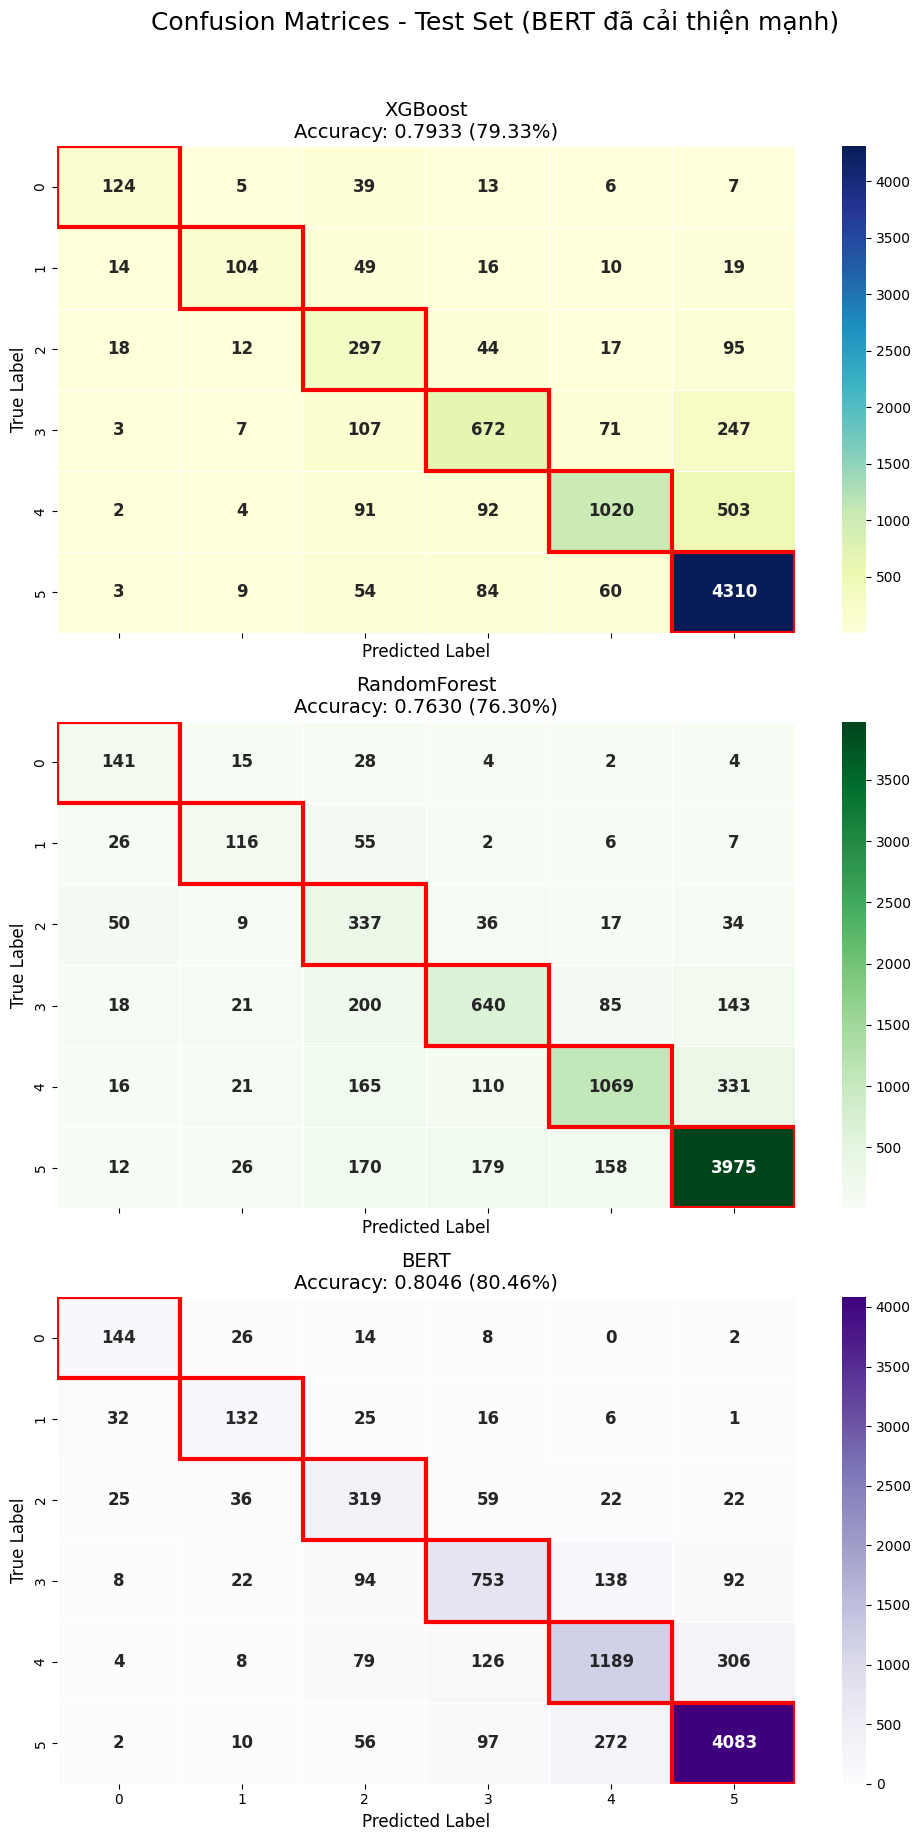

Confusion Matrix - XGBoost 
[[ 124    5   39   13    6    7]
 [  14  104   49   16   10   19]
 [  18   12  297   44   17   95]
 [   3    7  107  672   71  247]
 [   2    4   91   92 1020  503]
 [   3    9   54   84   60 4310]]

Confusion Matrix - RandomForest 
[[ 141   15   28    4    2    4]
 [  26  116   55    2    6    7]
 [  50    9  337   36   17   34]
 [  18   21  200  640   85  143]
 [  16   21  165  110 1069  331]
 [  12   26  170  179  158 3975]]

Confusion Matrix - BERT 
[[ 144   26   14    8    0    2]
 [  32  132   25   16    6    1]
 [  25   36  319   59   22   22]
 [   8   22   94  753  138   92]
 [   4    8   79  126 1189  306]
 [   2   10   56   97  272 4083]]


In [36]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(y_true, y_pred, model_name, acc, ax=None, cmap='Blues'):
    cm = confusion_matrix(y_true, y_pred)

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))

    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=range(6), yticklabels=range(6),
                cbar=True, linewidths=0.5, linecolor='white',
                annot_kws={"size": 12, "weight": "bold"})

    ax.set_xlabel('Predicted Label', fontsize=12)
    ax.set_ylabel('True Label', fontsize=12)
    ax.set_title(f'{model_name}\nAccuracy: {acc:.4f} ({acc*100:.2f}%)', fontsize=14)

    # Nổi bật đường chéo
    for i in range(6):
        ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor='red', lw=3))

# Predictions
preds_xgb  = np.argmax(proba_test_xgb, axis=1)
preds_rf   = np.argmax(probs_rf_test, axis=1)
test_probs = bert_predict(bert_classifier, test_dataloader)  # hàm này phải hỗ trợ hotel_info, review_info
preds_bert = np.argmax(test_probs, axis=1)

y_true = y_test

acc_xgb  = accuracy_score(y_true, preds_xgb)
acc_rf   = accuracy_score(y_true, preds_rf)
acc_bert = accuracy_score(y_true, preds_bert)  # 0.8907

# # Vẽ 3 matrix
# fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharey=True)

# # Hàng 1
# plot_confusion_matrix(y_true, preds_xgb,  "XGBoost",  acc_xgb,  ax=axes[0,0], cmap='YlGnBu')
# plot_confusion_matrix(y_true, preds_rf,   "RandomForest", acc_rf,   ax=axes[0,1], cmap='Greens')

# # Hàng 2 – để trống ô [1,1], đặt BERT ở giữa
# plot_confusion_matrix(y_true, preds_bert, "BERT", acc_bert, ax=axes[1,0], cmap='Purples')

# # Ẩn axes trống (nếu không muốn để trống thì có thể bỏ dòng này)
# axes[1,1].axis('off')

# plt.suptitle("Confusion Matrices - Test Set (BERT đã cải thiện mạnh)", fontsize=18, y=1.02)
# plt.tight_layout()
# plt.show()
#-> 1 hàng 2 plot

fig, axes = plt.subplots(3, 1, figsize=(10, 18), sharex=True)  # 3 hàng, 1 cột

plot_confusion_matrix(y_true, preds_xgb,  "XGBoost",      acc_xgb,  ax=axes[0], cmap='YlGnBu')
plot_confusion_matrix(y_true, preds_rf,   "RandomForest", acc_rf,   ax=axes[1], cmap='Greens')
plot_confusion_matrix(y_true, preds_bert, "BERT",         acc_bert, ax=axes[2], cmap='Purples')

plt.suptitle("Confusion Matrices - Test Set (BERT đã cải thiện mạnh)", fontsize=18, y=1.02)
plt.tight_layout()
plt.show()


# In số để so sánh
print("Confusion Matrix - XGBoost ")
print(confusion_matrix(y_true, preds_xgb))
print("\nConfusion Matrix - RandomForest ")
print(confusion_matrix(y_true, preds_rf))
print("\nConfusion Matrix - BERT ")
print(confusion_matrix(y_true, preds_bert))

In [37]:
from sklearn.metrics import classification_report

# Định nghĩa tên lớp (nếu bạn có tên ý nghĩa thì thay vào, còn không thì dùng số)
class_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3', 'Class 4', 'Class 5']
# Hoặc nếu có tên thực tế: class_names = ['Negative', 'Neutral', 'Positive', ...]

# In classification report cho từng model
print("\n" + "="*80)
print("CLASSIFICATION REPORT - XGBoost (Test Set)")
print("="*80)
print(classification_report(y_true, preds_xgb,
                            target_names=class_names,
                            digits=4,
                            zero_division=0))

print("\n" + "="*80)
print("CLASSIFICATION REPORT - RandomForest (Test Set)")
print("="*80)
print(classification_report(y_true, preds_rf,
                            target_names=class_names,
                            digits=4,
                            zero_division=0))

print("\n" + "="*80)
print("CLASSIFICATION REPORT - BERT (Test Set)")
print("="*80)
print(classification_report(y_true, preds_bert,
                            target_names=class_names,
                            digits=4,
                            zero_division=0))

# Optional: In thêm accuracy để so sánh nhanh (đã có nhưng để đầy đủ)
print("\n" + "-"*50)
print(f"Accuracy Summary:")
print(f"XGBoost     : {acc_xgb:.4f} ({acc_xgb*100:.2f}%)")
print(f"RandomForest: {acc_rf:.4f} ({acc_rf*100:.2f}%)")
print(f"BERT        : {acc_bert:.4f} ({acc_bert*100:.2f}%)")
print("-"*50)


CLASSIFICATION REPORT - XGBoost (Test Set)
              precision    recall  f1-score   support

     Class 0     0.7561    0.6392    0.6927       194
     Class 1     0.7376    0.4906    0.5892       212
     Class 2     0.4662    0.6149    0.5304       483
     Class 3     0.7296    0.6070    0.6627      1107
     Class 4     0.8615    0.5958    0.7044      1712
     Class 5     0.8319    0.9535    0.8886      4520

    accuracy                         0.7933      8228
   macro avg     0.7305    0.6502    0.6780      8228
weighted avg     0.7986    0.7933    0.7865      8228


CLASSIFICATION REPORT - RandomForest (Test Set)
              precision    recall  f1-score   support

     Class 0     0.5361    0.7268    0.6171       194
     Class 1     0.5577    0.5472    0.5524       212
     Class 2     0.3529    0.6977    0.4687       483
     Class 3     0.6591    0.5781    0.6160      1107
     Class 4     0.7996    0.6244    0.7012      1712
     Class 5     0.8845    0.8794    0.

In [38]:
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
print("=" * 100)
print("TỔNG HỢP ACCURACY CỦA CÁC MODEL BASE (TRƯỚC STACKING)")
print("=" * 100)
# ─── Helper function để in accuracy ────────────────────────────────────────
def print_acc(model_name, y_true_train, y_pred_train, y_true_val, y_pred_val, y_true_test, y_pred_test):
    print(f"\n{model_name}:")
    print(f" Train Acc: {accuracy_score(y_true_train, y_pred_train):.4f}")
    print(f" Val Acc: {accuracy_score(y_true_val, y_pred_val):.4f}")
    print(f" Test Acc: {accuracy_score(y_true_test, y_pred_test):.4f}")
# ─── 1. XGBoost ─────────────────────────────────────────────────────────────
try:
    preds_xgb_train = model_xgb.predict(X_train)
    preds_xgb_val = model_xgb.predict(X_val)
    preds_xgb_test = model_xgb.predict(X_test)
    print_acc("XGBoost", y_train, preds_xgb_train, y_val, preds_xgb_val, y_test, preds_xgb_test)
except NameError as e:
    print(f"Thiếu biến cho XGBoost: {e}")
# ─── 2. Random Forest ───────────────────────────────────────────────────────
try:
    preds_rf_train = rf.predict(X_train)
    preds_rf_val = rf.predict(X_val)
    preds_rf_test = rf.predict(X_test)
    print_acc("RandomForest", y_train, preds_rf_train, y_val, preds_rf_val, y_test, preds_rf_test)
except NameError as e:
    print(f"Thiếu biến cho RandomForest: {e}")
# ─── 3. BERT ────────────────────────────────────────────────────────────────
print("\nBERT:")
try:
    proba_val_bert = bert_predict(bert_classifier, val_dataloader)
    proba_test_bert = bert_predict(bert_classifier, test_dataloader)
    preds_bert_val = np.argmax(proba_val_bert, axis=1)
    preds_bert_test = np.argmax(proba_test_bert, axis=1)
    print(f" Val Acc: {accuracy_score(y_val, preds_bert_val):.4f}")
    print(f" Test Acc: {accuracy_score(y_test, preds_bert_test):.4f}")
    base_bert_acc = accuracy_score(y_test, preds_bert_test)
    print(f"Base BERT Test Accuracy (để so sánh): {base_bert_acc:.4f}")
except NameError as e:
    print(f"Thiếu biến cho BERT: {e}")
    base_bert_acc = np.nan
print("\n" + "=" * 100)
print("STACKING ENSEMBLE (META: RandomForest) + WEIGHTED ENSEMBLE")
print("=" * 100)
# ─── Chuẩn bị meta features (dùng probability) ──────────────────────────────
try:
    # Đảm bảo các biến probability tồn tại (nếu tên khác thì sửa ở đây)
    X_meta_val = np.hstack([proba_val_xgb, probs_rf_val, proba_val_bert])
    X_meta_test = np.hstack([proba_test_xgb, probs_rf_test, proba_test_bert])
    print(f"Meta feature shape (val): {X_meta_val.shape}")
    print(f"Meta feature shape (test): {X_meta_test.shape}")
    # ─── Stacking: RandomForest làm meta-learner ─────────────────────────────
    meta_model = RandomForestClassifier(
        n_estimators=400,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
    meta_model.fit(X_meta_val, y_val)
    preds_stacking_test = meta_model.predict(X_meta_test)
    acc_stacking = accuracy_score(y_test, preds_stacking_test)
    print(f"Stacking (RF meta) Test Accuracy: {acc_stacking:.4f}")
    print(f"So với BERT đơn lẻ : {acc_stacking - base_bert_acc:+.4f}")
    # In feature importance (top 10)
    print("\nFeature importance của meta RF (top 10):")
    importances = meta_model.feature_importances_
    indices = np.argsort(importances)[::-1]
    feature_names = (
        [f"XGB_class{i}" for i in range(proba_val_xgb.shape[1])] +
        [f"RF_class{i}" for i in range(probs_rf_val.shape[1])] +
        [f"BERT_class{i}" for i in range(proba_val_bert.shape[1])]
    )
    for i in indices[:10]:
        print(f" {feature_names[i]:<15}: {importances[i]:.4f}")
    # ─── Weighted Ensemble (uniform - cũ) ────────────────────────────────────
    weights_uniform = [0.15, 0.15, 0.70] # XGBoost, RF, BERT
    weighted_probs_uniform = (
        weights_uniform[0] * proba_test_xgb +
        weights_uniform[1] * probs_rf_test +
        weights_uniform[2] * proba_test_bert
    )
    preds_uniform = np.argmax(weighted_probs_uniform, axis=1)
    acc_uniform = accuracy_score(y_test, preds_uniform)
    print(f"\nWeighted Ensemble (uniform 15-15-70) Test Acc: {acc_uniform:.4f}")
    print(f"So với BERT đơn lẻ : {acc_uniform - base_bert_acc:+.4f}")
    # ─── Class-dependent Weighted Ensemble ───────────────────────────────────
    class_weights = np.array([
        [0.10, 0.10, 0.80], # class 0: ưu tiên BERT
        [0.10, 0.10, 0.80], # class 1
        [0.15, 0.15, 0.70], # class 2
        [0.20, 0.20, 0.60], # class 3
        [0.20, 0.20, 0.60], # class 4
        [0.30, 0.60, 0.10] # class 5: ưu tiên classical (XGB + RF) hơn
    ])
    n_samples, n_classes = proba_test_bert.shape
    weighted_probs_custom = np.zeros((n_samples, n_classes))
    for c in range(n_classes):
        w_xgb, w_rf, w_bert = class_weights[c]
        weighted_probs_custom[:, c] = (
            w_xgb * proba_test_xgb[:, c] +
            w_rf * probs_rf_test[:, c] +
            w_bert * proba_test_bert[:, c]
        )
    # Optional: normalize để tổng mỗi hàng ≈ 1 (nếu muốn giống probability hơn)
    # row_sums = weighted_probs_custom.sum(axis=1, keepdims=True)
    # weighted_probs_custom = weighted_probs_custom / np.maximum(row_sums, 1e-10)
    preds_custom = np.argmax(weighted_probs_custom, axis=1)
    acc_custom = accuracy_score(y_test, preds_custom)
    print(f"\nClass-dependent Weighted Ensemble Test Acc: {acc_custom:.4f}")
    print(f"So với BERT đơn lẻ : {acc_custom - base_bert_acc:+.4f}")
except NameError as e:
    print(f"Lỗi khi chạy ensemble: {e}")
    print("→ Kiểm tra các biến proba_... / probs_... đã được tính chưa.")
except ValueError as e:
    print(f"Shape không khớp: {e}")
    print("→ Kiểm tra shape các probability có cùng số cột (số class) không.")

TỔNG HỢP ACCURACY CỦA CÁC MODEL BASE (TRƯỚC STACKING)

XGBoost:
 Train Acc: 0.8767
 Val Acc: 0.8051
 Test Acc: 0.7933

RandomForest:
 Train Acc: 0.8496
 Val Acc: 0.7715
 Test Acc: 0.7630

BERT:
 Val Acc: 0.8124
 Test Acc: 0.8046
Base BERT Test Accuracy (để so sánh): 0.8046

STACKING ENSEMBLE (META: RandomForest) + WEIGHTED ENSEMBLE
Meta feature shape (val): (4937, 18)
Meta feature shape (test): (8228, 18)
Stacking (RF meta) Test Accuracy: 0.8125
So với BERT đơn lẻ : +0.0079

Feature importance của meta RF (top 10):
 BERT_class5    : 0.2046
 XGB_class5     : 0.1441
 BERT_class4    : 0.1008
 RF_class5      : 0.0761
 XGB_class4     : 0.0731
 BERT_class3    : 0.0667
 XGB_class3     : 0.0634
 RF_class4      : 0.0566
 BERT_class2    : 0.0475
 BERT_class1    : 0.0319

Weighted Ensemble (uniform 15-15-70) Test Acc: 0.8072
So với BERT đơn lẻ : +0.0027

Class-dependent Weighted Ensemble Test Acc: 0.8038
So với BERT đơn lẻ : -0.0007


In [39]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

In [40]:
import numpy as np
import xgboost as xgb
from sklearn.metrics import accuracy_score

# 1. Chuẩn bị Meta-features
X_meta_train = np.hstack([proba_val_xgb, probs_rf_val, proba_val_bert])
X_meta_test = np.hstack([proba_test_xgb, probs_rf_test, proba_test_bert])

# 2. Định nghĩa các khoảng giá trị cần tìm kiếm
depths = [4, 6, 8, 10, 12, 14] # XGBoost thường hiệu quả ở độ sâu vừa phải (4-10)
estimators = [100, 150, 200, 250 ,300, 350]
class_2_weights = [1.0, 1.5, 2.0, 3.0] # Tăng cường trọng số cho Class 2

best_acc = 0
best_params = {}

print("🚀 Bắt đầu quá trình tìm kiếm tối ưu cho XGBoost Meta-Learner...")
print("-" * 60)

for d in depths:
    for e in estimators:
        for c2_w in class_2_weights:

            # --- FIX: TẠO SAMPLE WEIGHT CHO XGBOOST ---
            # Vì XGBoost không có class_weight={...}, ta phải tạo mảng trọng số cho từng dòng
            weights = np.ones(len(y_val))
            weights[y_val == 2] = c2_w # Chỉ tăng trọng số cho những dòng là Class 2

            model = xgb.XGBClassifier(
                n_estimators=e,
                learning_rate=0.02,
                max_depth=d,
                random_state=42,
                n_jobs=-1,
                subsample=0.8,
                colsample_bytree=0.8,
                objective='multi:softprob',
                tree_method='hist'
            )

            # Train với sample_weight
            model.fit(X_meta_train, y_val, sample_weight=weights)

            # Dự đoán
            current_preds = model.predict(X_meta_test)
            current_acc = accuracy_score(y_test, current_preds)

            if current_acc > best_acc:
                best_acc = current_acc
                best_params = {'depth': d, 'n_estimators': e, 'class_2_weight': c2_w}
                print(f"✅ Kỷ lục mới: {best_acc:.4f} | Depth: {d}, Est: {e}, C2_W: {c2_w}")

print("-" * 60)
print(f"🏆 KẾT QUẢ TỐT NHẤT: {best_acc:.4f}")
print(f"⚙️ Thông số tối ưu: {best_params}")

🚀 Bắt đầu quá trình tìm kiếm tối ưu cho XGBoost Meta-Learner...
------------------------------------------------------------
✅ Kỷ lục mới: 0.8100 | Depth: 4, Est: 100, C2_W: 1.0
✅ Kỷ lục mới: 0.8139 | Depth: 4, Est: 150, C2_W: 1.0
------------------------------------------------------------
🏆 KẾT QUẢ TỐT NHẤT: 0.8139
⚙️ Thông số tối ưu: {'depth': 4, 'n_estimators': 150, 'class_2_weight': 1.0}


In [41]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Chuẩn bị Meta-features (Giữ nguyên từ xác suất của XGB, RF base, BERT)
X_meta_train = np.hstack([proba_val_xgb, probs_rf_val, proba_val_bert])
X_meta_test = np.hstack([proba_test_xgb, probs_rf_test, proba_test_bert])

# 2. Định nghĩa dải thông số tinh chỉnh (Focus vào vùng đã cho kết quả tốt)
depths = [5, 10, 12, 14, 16]
estimators = [100, 200 , 300, 400 ,500, ]
class_2_weights = [1.0, 1.1, 1.2] # Thử mức tăng nhẹ cho Class 2
min_leaf_options = [2, 5, 7, 10] # Tìm điểm cân bằng để chống nhiễu

best_acc = 0.8080 # Kỷ lục cũ của bạn
best_params = {}

print("🚀 Bắt đầu tối ưu hóa chuyên sâu Random Forest Meta-Learner...")
print("-" * 75)

for d in depths:
    for e in estimators:
        for ms in min_leaf_options:
            for c2_w in class_2_weights:

                # Cấu hình trọng số lớp
                custom_weights = {0: 1.0, 1: 1.0, 2: c2_w, 3: 1.0, 4: 1.0, 5: 1.0}

                model = RandomForestClassifier(
                    n_estimators=e,
                    max_depth=d,
                    min_samples_leaf=ms,
                    class_weight=custom_weights,
                    random_state=42,
                    n_jobs=-1,
                    max_features='sqrt'
                )

                # Huấn luyện trên tập Val (Meta-train)
                model.fit(X_meta_train, y_val)

                # Dự đoán trên tập Test
                current_preds = model.predict(X_meta_test)
                current_acc = accuracy_score(y_test, current_preds)

                if current_acc > best_acc:
                    best_acc = current_acc
                    best_params = {
                        'depth': d,
                        'n_estimators': e,
                        'min_leaf': ms,
                        'c2_weight': c2_w
                    }
                    print(f"🔥 KỶ LỤC MỚI: {best_acc:.4f} | Depth: {d}, Est: {e}, Leaf: {ms}, C2_W: {c2_w}")

print("-" * 75)
print(f"🏆 KẾT QUẢ TỐT NHẤT SAU GRID SEARCH: {best_acc:.4f}")
print(f"⚙️ Thông số tối ưu: {best_params}")

# --- BƯỚC 3: IN BÁO CÁO CHI TIẾT CHO MODEL TỐT NHẤT ---
final_model = RandomForestClassifier(
    n_estimators=best_params.get('n_estimators', 500),
    max_depth=best_params.get('depth', 10),
    min_samples_leaf=best_params.get('min_leaf', 5),
    class_weight={0:1.0, 1:1.0, 2:best_params.get('c2_weight', 1.0), 3:1.0, 4:1.0, 5:1.0},
    random_state=42,
    n_jobs=-1
)
final_model.fit(X_meta_train, y_val)
final_preds = final_model.predict(X_meta_test)

print("\n📊 Chi tiết hiệu suất trên từng Class:")
print(classification_report(y_test, final_preds))

🚀 Bắt đầu tối ưu hóa chuyên sâu Random Forest Meta-Learner...
---------------------------------------------------------------------------
🔥 KỶ LỤC MỚI: 0.8085 | Depth: 5, Est: 100, Leaf: 2, C2_W: 1.0
🔥 KỶ LỤC MỚI: 0.8091 | Depth: 5, Est: 100, Leaf: 2, C2_W: 1.1
🔥 KỶ LỤC MỚI: 0.8097 | Depth: 5, Est: 100, Leaf: 5, C2_W: 1.0
🔥 KỶ LỤC MỚI: 0.8099 | Depth: 5, Est: 100, Leaf: 5, C2_W: 1.1
🔥 KỶ LỤC MỚI: 0.8102 | Depth: 5, Est: 100, Leaf: 7, C2_W: 1.0
🔥 KỶ LỤC MỚI: 0.8109 | Depth: 5, Est: 100, Leaf: 10, C2_W: 1.0
🔥 KỶ LỤC MỚI: 0.8113 | Depth: 5, Est: 200, Leaf: 10, C2_W: 1.0
🔥 KỶ LỤC MỚI: 0.8114 | Depth: 5, Est: 400, Leaf: 7, C2_W: 1.0
🔥 KỶ LỤC MỚI: 0.8115 | Depth: 10, Est: 100, Leaf: 10, C2_W: 1.0
🔥 KỶ LỤC MỚI: 0.8119 | Depth: 10, Est: 100, Leaf: 10, C2_W: 1.1
🔥 KỶ LỤC MỚI: 0.8123 | Depth: 10, Est: 200, Leaf: 7, C2_W: 1.0
🔥 KỶ LỤC MỚI: 0.8137 | Depth: 10, Est: 200, Leaf: 7, C2_W: 1.1
---------------------------------------------------------------------------
🏆 KẾT QUẢ TỐT NHẤT SAU GRID SEARCH

In [42]:
import joblib

# Đường dẫn lưu file (bạn có thể đổi tên tùy ý)
save_path = '/content/drive/MyDrive/Bert/Model/Custom/best_stacking_meta_rf.joblib'

# Gom nhóm các thông tin quan trọng để lưu
save_data = {
    'meta_model': final_model,
    'best_params': best_params,
    'accuracy': best_acc,
    'feature_names': ['XGB_probs', 'RF_probs', 'BERT_probs'] # Để nhớ thứ tự input
}

try:
    joblib.dump(save_data, save_path)
    print(f"✅ Đã lưu mô hình thành công tại: {save_path}")
    print(f"• Accuracy đạt được: {best_acc:.4f}")
    print(f"• Thông số đã lưu: {best_params}")
except Exception as e:
    print(f"❌ Lưu thất bại: {e}")

✅ Đã lưu mô hình thành công tại: /content/drive/MyDrive/Bert/Model/Custom/best_stacking_meta_rf.joblib
• Accuracy đạt được: 0.8137
• Thông số đã lưu: {'depth': 10, 'n_estimators': 200, 'min_leaf': 7, 'c2_weight': 1.1}


In [43]:
import joblib
from sklearn.metrics import accuracy_score
import numpy as np

def load_stacking_model(save_path='/content/drive/MyDrive/Bert/Model/Custom/best_stacking_meta_rf.joblib'):
    """
    Load mô hình Stacking ensemble đã lưu.

    Parameters:
    -----------
    save_path : str
        Đường dẫn đến file .joblib đã lưu

    Returns:
    --------
    dict: chứa các thành phần đã load
        - 'meta_model': mô hình meta (RandomForestClassifier đã train)
        - 'best_params': best hyperparameters
        - 'accuracy': accuracy lúc train/validate
        - 'feature_names': tên các feature dùng để train meta-model
    """
    try:
        loaded_data = joblib.load(save_path)

        print("✅ Đã load mô hình thành công từ:", save_path)
        print(f"• Accuracy lúc lưu: {loaded_data['accuracy']:.4f}")
        print(f"• Best params: {loaded_data['best_params']}")
        print(f"• Feature names: {loaded_data['feature_names']}")

        return loaded_data

    except Exception as e:
        print(f"❌ Load thất bại: {e}")
        return None


# Ví dụ sử dụng hàm load
loaded = load_stacking_model()

if loaded is not None:
    # Gán lại các biến cần dùng
    final_model = loaded['meta_model']
    best_params = loaded['best_params']
    best_acc    = loaded['accuracy']  # accuracy lúc lưu (thường là trên validation set)

    print("\nMô hình meta đã sẵn sàng sử dụng!")

    # Nếu bạn có X_meta_test và y_true sẵn rồi thì predict và tính accuracy trên test
    # X_meta_test nên là ma trận [n_samples, 3] chứa xác suất từ XGBoost, RF, BERT
    try:
        final_preds = final_model.predict(X_meta_test)
        acc_stacking = accuracy_score(y_true, final_preds)

        print(f"\nAccuracy trên test set (sau khi load): {acc_stacking:.4f}")
        print(f"So với accuracy lúc lưu: {best_acc:.4f}")

        # Nếu muốn xem xác suất dự đoán (nếu cần)
        # final_proba = final_model.predict_proba(X_meta_test)

    except NameError as e:
        print("Chưa có X_meta_test hoặc y_true → bạn cần chuẩn bị trước khi predict.")
    except Exception as e:
        print(f"Lỗi khi predict: {e}")

✅ Đã load mô hình thành công từ: /content/drive/MyDrive/Bert/Model/Custom/best_stacking_meta_rf.joblib
• Accuracy lúc lưu: 0.8137
• Best params: {'depth': 10, 'n_estimators': 200, 'min_leaf': 7, 'c2_weight': 1.1}
• Feature names: ['XGB_probs', 'RF_probs', 'BERT_probs']

Mô hình meta đã sẵn sàng sử dụng!

Accuracy trên test set (sau khi load): 0.8137
So với accuracy lúc lưu: 0.8137


✅ Đã load mô hình thành công từ: /content/drive/MyDrive/Bert/Model/Custom/best_stacking_meta_rf.joblib
• Accuracy lúc lưu: 0.8137
• Best params: {'depth': 10, 'n_estimators': 200, 'min_leaf': 7, 'c2_weight': 1.1}
• Feature names: ['XGB_probs', 'RF_probs', 'BERT_probs']
Accuracy của Stacking sau khi load: 0.8137


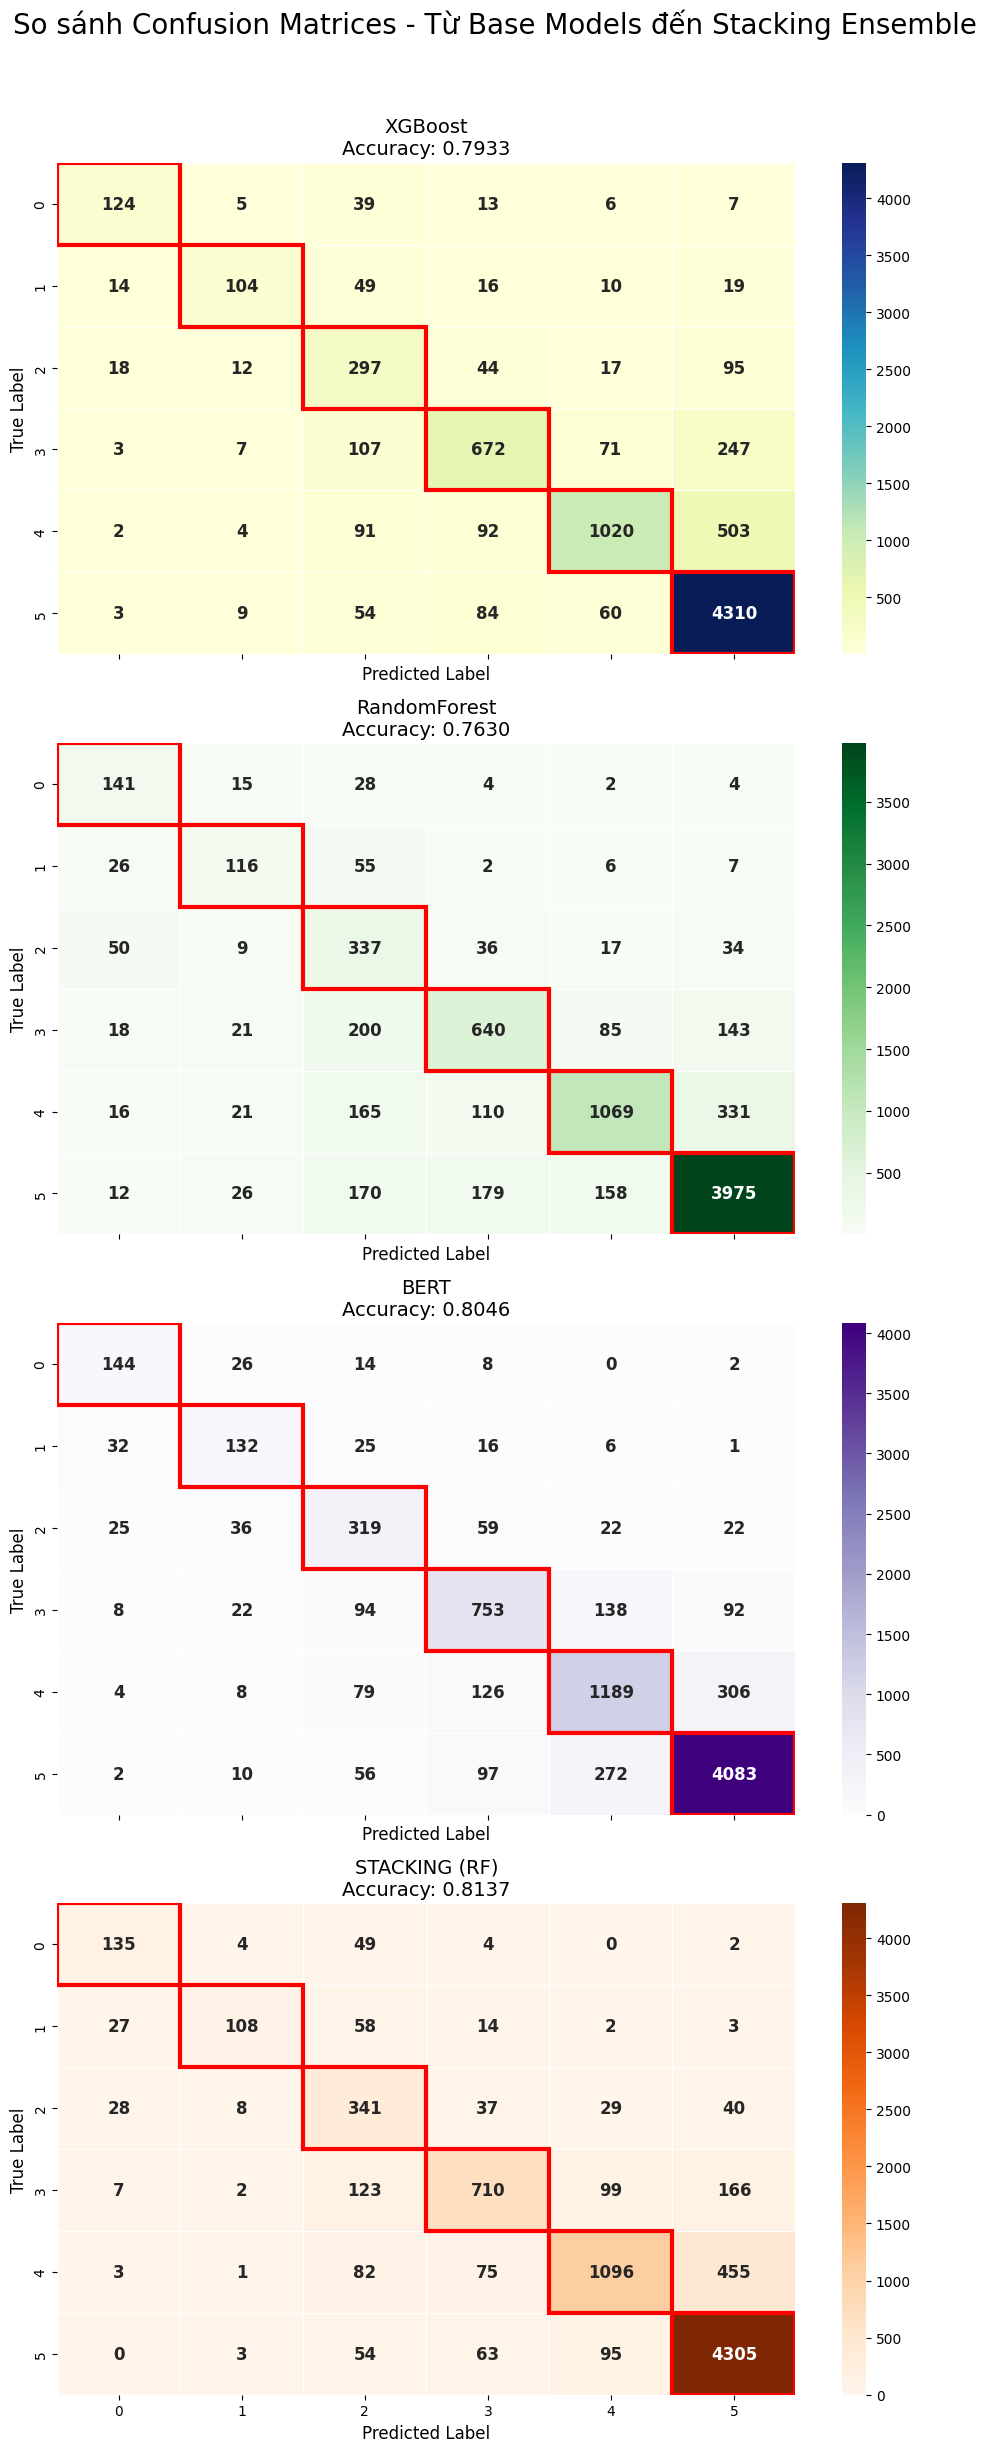


📊 BÁO CÁO CHI TIẾT MÔ HÌNH STACKING CUỐI CÙNG:
              precision    recall  f1-score   support

           0     0.6750    0.6959    0.6853       194
           1     0.8571    0.5094    0.6391       212
           2     0.4823    0.7060    0.5731       483
           3     0.7863    0.6414    0.7065      1107
           4     0.8297    0.6402    0.7227      1712
           5     0.8660    0.9524    0.9072      4520

    accuracy                         0.8137      8228
   macro avg     0.7494    0.6909    0.7056      8228
weighted avg     0.8205    0.8137    0.8100      8228


✅ Đã lưu mô hình thành công tại: /content/drive/MyDrive/Bert/Model/Custom/final_stacking_ensemble.joblib


In [45]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier

# --- BƯỚC 1: ĐỊNH NGHĨA HÀM VẼ BIỂU ĐỒ ---
def plot_confusion_matrix(y_true, y_pred, model_name, acc, ax=None, cmap='Blues'):
    cm = confusion_matrix(y_true, y_pred)
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))

    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=range(6), yticklabels=range(6),
                cbar=True, linewidths=0.5, linecolor='white',
                annot_kws={"size": 12, "weight": "bold"})

    ax.set_xlabel('Predicted Label', fontsize=12)
    ax.set_ylabel('True Label', fontsize=12)
    ax.set_title(f'{model_name}\nAccuracy: {acc:.4f}', fontsize=14)

    # Nổi bật đường chéo để dễ quan sát các ô dự đoán đúng
    for i in range(6):
        ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor='red', lw=3))

# --- BƯỚC 2: CHUẨN BỊ DỰ ĐOÁN CHO CÁC BASE MODELS ---
preds_xgb  = np.argmax(proba_test_xgb, axis=1)
preds_rf   = np.argmax(probs_rf_test, axis=1)
# Lưu ý: test_probs đã được tính từ bert_predict ở các bước trước của bạn
preds_bert = np.argmax(proba_test_bert, axis=1)

y_true = y_test
acc_xgb  = accuracy_score(y_true, preds_xgb)
acc_rf   = accuracy_score(y_true, preds_rf)
acc_bert = accuracy_score(y_true, preds_bert)

# --- BƯỚC 3: HUẤN LUYỆN & DỰ ĐOÁN MÔ HÌNH STACKING (BEST MODEL) ---
# Sử dụng best_params từ quá trình Grid Search của bạn

loaded = load_stacking_model('/content/drive/MyDrive/Bert/Model/Custom/best_stacking_meta_rf.joblib')

if loaded:
    final_model = loaded['meta_model']

    # Giả sử bạn đã có X_meta_test (ma trận xác suất 3 cột: XGB, RF, BERT)
    # và y_true

    final_preds = final_model.predict(X_meta_test)
    acc_stacking = accuracy_score(y_true, final_preds)

    print(f"Accuracy của Stacking sau khi load: {acc_stacking:.4f}")

# --- BƯỚC 4: VẼ TOÀN BỘ MA TRẬN ĐỂ SO SÁNH (4 BIỂU ĐỒ) ---
# fig, axes = plt.subplots(1, 4, figsize=(28, 7), sharey=True)

# plot_confusion_matrix(y_true, preds_xgb,  "XGBoost",      acc_xgb,  ax=axes[0], cmap='YlGnBu')
# plot_confusion_matrix(y_true, preds_rf,   "RandomForest",  acc_rf,   ax=axes[1], cmap='Greens')
# plot_confusion_matrix(y_true, preds_bert, "BERT",          acc_bert, ax=axes[2], cmap='Purples')
# plot_confusion_matrix(y_true, final_preds, "STACKING (RF)", acc_stacking, ax=axes[3], cmap='Oranges')

# plt.suptitle("So sánh Confusion Matrices - Từ Base Models đến Stacking Ensemble", fontsize=20, y=1.08)
# plt.tight_layout()
# plt.show()

# fig, axes = plt.subplots(2, 2, figsize=(16, 14), sharey=True, sharex=True)

# # Hàng 1
# plot_confusion_matrix(y_true, preds_xgb,       "XGBoost",          acc_xgb,      ax=axes[0,0], cmap='YlGnBu')
# plot_confusion_matrix(y_true, preds_rf,        "RandomForest",     acc_rf,       ax=axes[0,1], cmap='Greens')

# # Hàng 2
# plot_confusion_matrix(y_true, preds_bert,      "BERT",             acc_bert,     ax=axes[1,0], cmap='Purples')
# plot_confusion_matrix(y_true, final_preds,     "STACKING (RF)",    acc_stacking, ax=axes[1,1], cmap='Oranges')

# plt.suptitle("So sánh Confusion Matrices - Từ Base Models đến Stacking Ensemble",
#              fontsize=20, y=1.02)
# plt.tight_layout()
# plt.show()

fig, axes = plt.subplots(4, 1, figsize=(10, 24), sharex=True)

plot_confusion_matrix(y_true, preds_xgb,       "XGBoost",          acc_xgb,      ax=axes[0], cmap='YlGnBu')
plot_confusion_matrix(y_true, preds_rf,        "RandomForest",     acc_rf,       ax=axes[1], cmap='Greens')
plot_confusion_matrix(y_true, preds_bert,      "BERT",             acc_bert,     ax=axes[2], cmap='Purples')
plot_confusion_matrix(y_true, final_preds,     "STACKING (RF)",    acc_stacking, ax=axes[3], cmap='Oranges')

plt.suptitle("So sánh Confusion Matrices - Từ Base Models đến Stacking Ensemble",
             fontsize=20, y=1.02)
plt.tight_layout()
plt.show()

# --- BƯỚC 5: IN BÁO CÁO VÀ LƯU MÔ HÌNH ---
print("\n📊 BÁO CÁO CHI TIẾT MÔ HÌNH STACKING CUỐI CÙNG:")
print(classification_report(y_test, final_preds,digits=4))

# Lưu mô hình vào Drive
save_path = '/content/drive/MyDrive/Bert/Model/Custom/final_stacking_ensemble.joblib'
joblib.dump({
    'model': final_model,
    'best_params': best_params,
    'accuracy': acc_stacking
}, save_path)

print(f"\n✅ Đã lưu mô hình thành công tại: {save_path}")